In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
df = pd.read_csv(r"d:\SQL\Jyts DS Course\Notebooks\X.csv")

target = pd.read_csv(r"d:\SQL\Jyts DS Course\Notebooks\target.csv")

df = df.join(target)

In [3]:
df

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,...,mths_since_recent_bankcard_delinq,mths_since_recent_revol_delinq,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year,y
0,2500,13.56,84.92,C1,Chef,10+ years,RENT,55000.0,Not Verified,debt_consolidation,...,NaN,NaN,Cash,36,Dec,2018,1,Apr,2001,0
1,30000,18.94,777.23,D2,Postmaster,10+ years,MORTGAGE,90000.0,Source Verified,debt_consolidation,...,NaN,NaN,Cash,60,Dec,2018,7,Jun,1987,0
2,5000,17.97,180.69,D1,Administrative,6 years,MORTGAGE,59280.0,Source Verified,debt_consolidation,...,NaN,NaN,Cash,36,Dec,2018,4,Apr,2011,0
3,4000,18.94,146.51,D2,IT Supervisor,10+ years,MORTGAGE,92000.0,Source Verified,debt_consolidation,...,NaN,NaN,Cash,36,Dec,2018,9,Feb,2006,0
4,30000,16.14,731.78,C4,Mechanic,10+ years,MORTGAGE,57250.0,Not Verified,debt_consolidation,...,NaN,NaN,Cash,60,Dec,2018,2,Dec,2000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2139638,30000,30.75,984.47,F5,Sales,6 years,MORTGAGE,100000.0,Verified,debt_consolidation,...,NaN,NaN,Cash,60,Oct,2017,3,Aug,1996,0
2139639,12000,14.08,279.72,C3,house keeper,10+ years,MORTGAGE,58000.0,Not Verified,debt_consolidation,...,NaN,NaN,Cash,60,Oct,2017,0,Jan,2004,0
2139640,10000,11.99,332.10,B5,Teacher,10+ years,OWN,64000.0,Source Verified,debt_consolidation,...,NaN,NaN,Cash,36,Oct,2017,6,Feb,1995,0
2139641,12000,21.45,327.69,D5,NaN,NaN,RENT,60000.0,Not Verified,debt_consolidation,...,9.0,7.0,Cash,60,Oct,2017,9,Jul,2003,0


In [4]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include='object').columns.tolist()

C:\Users\Diego Monegro\AppData\Local\Temp\ipykernel_21480\2478177545.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns.tolist()


In [5]:
df['Loss'] = 100 * df['max_bal_owed'] / df['funded_amnt']
df['Loss'].describe()

count    1.273987e+06
mean     5.172619e+01
std      7.275773e+01
min      0.000000e+00
25%      1.988929e+01
50%      3.550000e+01
75%      5.913333e+01
max      5.975715e+03
Name: Loss, dtype: float64

In [6]:
df = df[df['Loss'] < 300]

In [7]:
df.isnull().sum()

funded_amnt                                0
interest_rate                              0
monthly_payment                            0
grade                                      0
emp_title                              97144
emp_length                             85670
home_ownership_status                      0
annual_income                              0
verification_status                        0
loan_purpose                               0
addr_state                                 0
dept_paym_income_ratio                     0
num_30+_delinq_in_2yrs                     0
num_inq_in_6mths                           0
mths_since_last_delinq                637781
num_open_credit_lines                      0
num_derogatory_pub_rec                     0
total_credit_revolving_bal                 0
used_credit_share                          0
tot_num_credit_lines                       0
initial_list_status                        0
remaining_princ_for_tot_amnt_fund          0
paym_rec_f

In [8]:
# Imputación de emp_title / emp_length y clasificación por sector
# (todo está en employment_sector.py, en la misma carpeta que este notebook)
from employment_sector import build_employment_features

df = build_employment_features(df)
df[['emp_title', 'emp_length', 'employment_sector']].isna().sum()

emp_title            0
emp_length           0
employment_sector    0
dtype: int64

In [9]:
df['emp_title'].value_counts()

emp_title
Unknown Employment Profile      78072
Manager                         21474
Teacher                         21368
Owner                           15500
Driver                          10329
                                ...  
Instructor / Lab Coordinator        1
Sales, Estimating & Design          1
SHIPPING MANGER                     1
Acft mechanic                       1
BABYSITTER                          1
Name: count, Length: 263133, dtype: int64

In [10]:
df[(df['emp_title'] == 'Unknown Other')]

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,...,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year,y,Loss,employment_sector


In [11]:
df[(df['emp_title'] == 'Unknown Other') & (df['emp_length'].notnull())]

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,...,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year,y,Loss,employment_sector


In [12]:
df['emp_length'].value_counts()

emp_length
10+ years                     423484
2 years                       116638
3 years                       103376
< 1 year                       98185
1 year                         85742
Unknown Length Profile         78457
4 years                        78430
5 years                        78293
6 years                        55751
8 years                        45237
7 years                        44935
9 years                        42254
Possible Pensioner Profile      7213
Name: count, dtype: int64

In [13]:
df[df['emp_title'] == 'Early-Carrer'].value_counts().sum()

np.int64(0)

In [14]:
df['grade'].value_counts()

grade
C1    84826
B5    84232
B4    78218
B1    73523
C2    72238
C3    71803
C4    71443
B2    71102
B3    70012
C5    68230
A1    60266
A5    58523
A4    55990
A3    45578
A2    43091
D1    41506
D2    38893
D3    34283
D4    28175
D5    23728
E1    14254
E2    11945
E5    11519
E3    11380
E4     9966
F1     5711
F2     3653
F3     3079
F4     2477
F5     2309
G1     1896
G2     1227
G3     1040
G4      972
G5      907
Name: count, dtype: int64

In [15]:
df

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,...,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year,y,Loss,employment_sector
0,2500,13.56,84.92,C1,Chef,10+ years,RENT,55000.0,Not Verified,debt_consolidation,...,Cash,36,Dec,2018,1,Apr,2001,0,85.480000,Hospitality & Food Service
1,30000,18.94,777.23,D2,Postmaster,10+ years,MORTGAGE,90000.0,Source Verified,debt_consolidation,...,Cash,60,Dec,2018,7,Jun,1987,0,3.326667,Transportation & Logistics
2,5000,17.97,180.69,D1,Administrative,6 years,MORTGAGE,59280.0,Source Verified,debt_consolidation,...,Cash,36,Dec,2018,4,Apr,2011,0,0.000000,Administration & HR
3,4000,18.94,146.51,D2,IT Supervisor,10+ years,MORTGAGE,92000.0,Source Verified,debt_consolidation,...,Cash,36,Dec,2018,9,Feb,2006,0,94.025000,Technology & Engineering
4,30000,16.14,731.78,C4,Mechanic,10+ years,MORTGAGE,57250.0,Not Verified,debt_consolidation,...,Cash,60,Dec,2018,2,Dec,2000,0,1.720000,Industrial & Skilled Trades
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2139638,30000,30.75,984.47,F5,Sales,6 years,MORTGAGE,100000.0,Verified,debt_consolidation,...,Cash,60,Oct,2017,3,Aug,1996,0,31.860000,Sales & Marketing
2139639,12000,14.08,279.72,C3,house keeper,10+ years,MORTGAGE,58000.0,Not Verified,debt_consolidation,...,Cash,60,Oct,2017,0,Jan,2004,0,33.766667,Hospitality & Food Service
2139640,10000,11.99,332.10,B5,Teacher,10+ years,OWN,64000.0,Source Verified,debt_consolidation,...,Cash,36,Oct,2017,6,Feb,1995,0,18.640000,Education & Training
2139641,12000,21.45,327.69,D5,Unknown Employment Profile,Unknown Length Profile,RENT,60000.0,Not Verified,debt_consolidation,...,Cash,60,Oct,2017,9,Jul,2003,0,20.050000,Unknown Employment Profile


In [16]:
print("Número real de filas:", len(df))
print("Índice máximo:", df.index.max())
print("Número de índices únicos:", df.index.nunique())
print("¿Índice consecutivo?:", df.index.equals(
    pd.RangeIndex(start=0, stop=len(df))
))

df = df.reset_index(drop=True)

Número real de filas: 1257995
Índice máximo: 2139642
Número de índices únicos: 1257995
¿Índice consecutivo?: False


In [17]:
df[df['emp_length'].isna()]

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,...,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year,y,Loss,employment_sector


<Axes: ylabel='emp_title'>

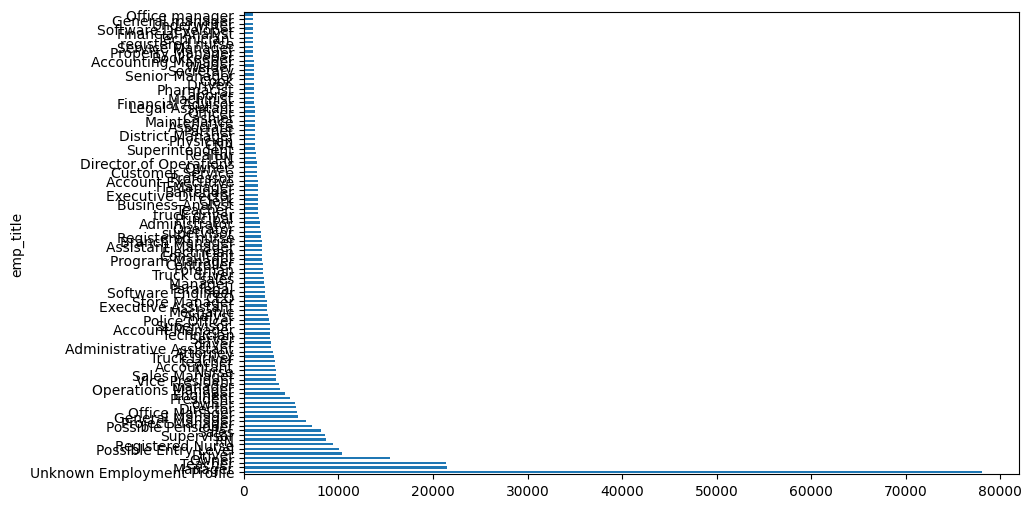

In [18]:
df['emp_title'].value_counts().head(100).plot(kind='barh', figsize=(10, 6))

In [19]:
df['emp_title'].value_counts().head(30)

emp_title
Unknown Employment Profile    78072
Manager                       21474
Teacher                       21368
Owner                         15500
Driver                        10329
Possible Entry-Level          10012
Registered Nurse               9471
RN                             8663
Supervisor                     8551
Sales                          8172
Possible Pensioner             7213
Project Manager                6531
General Manager                5708
Office Manager                 5563
Director                       5500
owner                          5362
President                      4856
Engineer                       4342
Operations Manager             3793
manager                        3739
Vice President                 3379
Sales Manager                  3365
Nurse                          3353
Accountant                     3313
teacher                        3305
Truck Driver                   3161
Attorney                       3089
Administrative Ass

In [20]:
from employment_sector import sector_distribution, unmatched_titles, check_titles

# Distribución de sectores
sector_distribution(df)

,employment_sector,count,percentage
0,Management & Executive,229210,18.22
1,Healthcare & Personal Care,111814,8.89
2,Industrial & Skilled Trades,105148,8.36
3,Technology & Engineering,103042,8.19
4,Unknown Employment Profile,78381,6.23
5,Finance & Accounting,78356,6.23
6,Transportation & Logistics,78109,6.21
7,Sales & Marketing,73498,5.84
8,Administration & HR,70881,5.63
9,Business & Professional Services,60731,4.83


In [21]:
# Títulos que no encajaron en ninguna regla ("Other Occupations")
unmatched_titles(df['emp_title']).head(50)

,normalized_title,count,cum_pct_of_other
0,cca,53,0.14
1,psa,39,0.25
2,liaison,35,0.34
3,msa,35,0.44
4,ssr,34,0.53
5,amt,34,0.62
6,dsa,29,0.70
7,fsa,28,0.78
8,monitor,26,0.85
9,rsc,24,0.91


In [22]:
# Verificación de los títulos revisados por lote
pd.set_option('display.max_rows', 300)
check_titles()

,emp_title,employment_sector,sector_detail,match_tier,normalized_title
0,Officer,Public Safety & Military,Public Safety,exact,officer
1,Forman,Industrial & Skilled Trades,Facilities & Skilled Trades,keywords,forman
2,Administrative,Administration & HR,Administration,keywords,administrative
3,Accounts Payable,Finance & Accounting,Finance & Accounting,keywords,accounts payable
4,Lead,Management & Executive,Management & Executive,generic,lead
5,Producer,Design & Creative,Design & Creative,keywords,producer
6,Lieutenant,Public Safety & Military,Public Safety,keywords,lieutenant
7,Specialist,Business & Professional Services,Business & Professional Services,generic,specialist
8,Correction Officer,Public Safety & Military,Public Safety,keywords,correction officer
9,Claims Adjuster,Finance & Accounting,Finance & Accounting,keywords,claims adjuster


In [23]:
df.head()

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,...,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year,y,Loss,employment_sector
0,2500,13.56,84.92,C1,Chef,10+ years,RENT,55000.0,Not Verified,debt_consolidation,...,Cash,36,Dec,2018,1,Apr,2001,0,85.480000,Hospitality & Food Service
1,30000,18.94,777.23,D2,Postmaster,10+ years,MORTGAGE,90000.0,Source Verified,debt_consolidation,...,Cash,60,Dec,2018,7,Jun,1987,0,3.326667,Transportation & Logistics
2,5000,17.97,180.69,D1,Administrative,6 years,MORTGAGE,59280.0,Source Verified,debt_consolidation,...,Cash,36,Dec,2018,4,Apr,2011,0,0.000000,Administration & HR
3,4000,18.94,146.51,D2,IT Supervisor,10+ years,MORTGAGE,92000.0,Source Verified,debt_consolidation,...,Cash,36,Dec,2018,9,Feb,2006,0,94.025000,Technology & Engineering
4,30000,16.14,731.78,C4,Mechanic,10+ years,MORTGAGE,57250.0,Not Verified,debt_consolidation,...,Cash,60,Dec,2018,2,Dec,2000,0,1.720000,Industrial & Skilled Trades


In [24]:
df['emp_length'].value_counts()


emp_length
10+ years                     423484
2 years                       116638
3 years                       103376
< 1 year                       98185
1 year                         85742
Unknown Length Profile         78457
4 years                        78430
5 years                        78293
6 years                        55751
8 years                        45237
7 years                        44935
9 years                        42254
Possible Pensioner Profile      7213
Name: count, dtype: int64

In [25]:

purpose = (
    df['loan_purpose']
    .astype('string')
    .str.strip()
    .str.lower()
)

purpose_mapping = {
    'debt_consolidation': 'Debt Consolidation',
    'credit_card': 'Credit Card',

    'home_improvement': 'Home & Property',
    'house': 'Home & Property',
    'renewable_energy': 'Home & Property',

    'other': 'Other',
    'wedding': 'Other',

    'major_purchase': 'Major Purchase',
    'educational': 'Major Purchase',

    'medical': 'Medical',
    'car': 'Vehicle',
    'small_business': 'Small Business',

    'vacation': 'Personal & Lifestyle',
    'moving': 'Personal & Lifestyle'
}

df['loan_purpose_group'] = (
    purpose.map(purpose_mapping)
    .fillna('Other')
)

# Resumen de categorías
purpose_summary = (
    df['loan_purpose_group']
    .value_counts()
    .rename_axis('loan_purpose_group')
    .reset_index(name='count')
)

purpose_summary['percentage'] = (
    purpose_summary['count'] / len(df) * 100
).round(2)

print(purpose_summary.to_string(index=False))

# Verificar valores originales no contemplados
print("\nValores originales sin correspondencia:")
print(
    purpose[
        purpose.notna() &
        ~purpose.isin(purpose_mapping.keys())
    ].value_counts()
)

  loan_purpose_group  count  percentage
  Debt Consolidation 690014       54.85
         Credit Card 291357       23.16
     Home & Property  98752        7.85
               Other  86389        6.87
      Major Purchase  30272        2.41
Personal & Lifestyle  18215        1.45
             Medical  15960        1.27
             Vehicle  13845        1.10
      Small Business  13191        1.05

Valores originales sin correspondencia:
Series([], Name: count, dtype: Int64)


In [26]:
df.drop('loan_purpose', axis=1, inplace=True)

In [27]:
cat_colsV4 = df.select_dtypes(include="object").columns.to_list()
df[cat_colsV4]

C:\Users\Diego Monegro\AppData\Local\Temp\ipykernel_21480\1120205374.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_colsV4 = df.select_dtypes(include="object").columns.to_list()


,grade,emp_title,emp_length,home_ownership_status,verification_status,addr_state,initial_list_status,disbursement_method,issue_date_month,earliest_cr_line_month,employment_sector,loan_purpose_group
0,C1,Chef,10+ years,RENT,Not Verified,NY,w,Cash,Dec,Apr,Hospitality & Food Service,Debt Consolidation
1,D2,Postmaster,10+ years,MORTGAGE,Source Verified,LA,w,Cash,Dec,Jun,Transportation & Logistics,Debt Consolidation
2,D1,Administrative,6 years,MORTGAGE,Source Verified,MI,w,Cash,Dec,Apr,Administration & HR,Debt Consolidation
3,D2,IT Supervisor,10+ years,MORTGAGE,Source Verified,WA,w,Cash,Dec,Feb,Technology & Engineering,Debt Consolidation
4,C4,Mechanic,10+ years,MORTGAGE,Not Verified,MD,w,Cash,Dec,Dec,Industrial & Skilled Trades,Debt Consolidation
...,...,...,...,...,...,...,...,...,...,...,...,...
1257990,F5,Sales,6 years,MORTGAGE,Verified,FL,f,Cash,Oct,Aug,Sales & Marketing,Debt Consolidation
1257991,C3,house keeper,10+ years,MORTGAGE,Not Verified,VT,w,Cash,Oct,Jan,Hospitality & Food Service,Debt Consolidation
1257992,B5,Teacher,10+ years,OWN,Source Verified,IL,w,Cash,Oct,Feb,Education & Training,Debt Consolidation
1257993,D5,Unknown Employment Profile,Unknown Length Profile,RENT,Not Verified,AK,w,Cash,Oct,Jul,Unknown Employment Profile,Debt Consolidation


In [28]:
length = (
    df['emp_length']
    .astype('string')
    .str.strip()
    .str.lower()
)

length_mapping = {
    '< 1 year': 'Entry-Level',
    '1 year': 'Entry-Level',

    '2 years': 'Early Career',
    '3 years': 'Early Career',

    '4 years': 'Mid-Career',
    '5 years': 'Mid-Career',
    '6 years': 'Mid-Career',

    '7 years': 'Experienced',
    '8 years': 'Experienced',
    '9 years': 'Experienced',

    '10+ years': 'Long Tenure',

    'unknown length profile': 'Unknown Length Profile',
    'possible pensioner profile': 'Possible Pensioner Profile'
}

df['emp_length_group'] = (
    length.map(length_mapping)
    .fillna('Unknown Length Profile')
)

# Revisar distribución
length_summary = (
    df['emp_length_group']
    .value_counts()
    .rename_axis('emp_length_group')
    .reset_index(name='count')
)

length_summary['percentage'] = (
    length_summary['count'] / len(df) * 100
).round(2)

print(length_summary.to_string(index=False))

# Detectar valores originales no contemplados
print("\nValores originales no contemplados:")
print(
    length[
        length.notna() &
        ~length.isin(length_mapping.keys())
    ].value_counts()
)

          emp_length_group  count  percentage
               Long Tenure 423484       33.66
              Early Career 220014       17.49
                Mid-Career 212474       16.89
               Entry-Level 183927       14.62
               Experienced 132426       10.53
    Unknown Length Profile  78457        6.24
Possible Pensioner Profile   7213        0.57

Valores originales no contemplados:
Series([], Name: count, dtype: Int64)


In [29]:
df.drop('emp_length', axis=1, inplace=True)

df[num_cols].isnull().sum()

funded_amnt                                0
interest_rate                              0
monthly_payment                            0
annual_income                              0
dept_paym_income_ratio                     0
num_30+_delinq_in_2yrs                     0
num_inq_in_6mths                           0
mths_since_last_delinq                637781
num_open_credit_lines                      0
num_derogatory_pub_rec                     0
total_credit_revolving_bal                 0
used_credit_share                          0
tot_num_credit_lines                       0
remaining_princ_for_tot_amnt_fund          0
paym_rec_for_tot_amnt_fund                 0
princ_rec                                  0
interest_rec                               0
late_fees_rec                              0
num_open_trades_in_6mths                   0
num_installment_acc_op_in_12mths           0
num_installment_acc_op_in_24mths           0
mths_since_last_installment_acc_op     39251
num_rev_tr

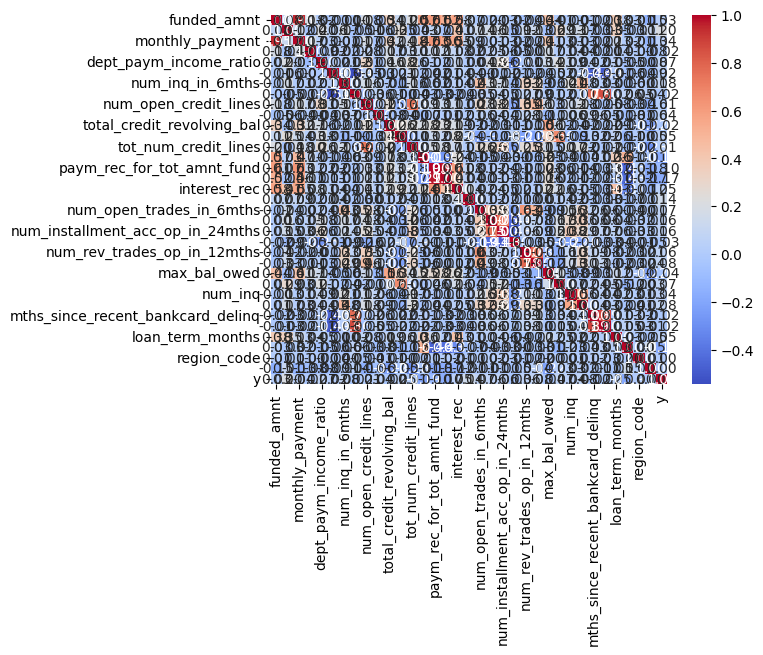

In [30]:
corr  = df[num_cols].corr()

import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

In [31]:
df = df.drop(
    columns=['princ_rec', 'paym_rec_for_tot_amnt_fund']
)

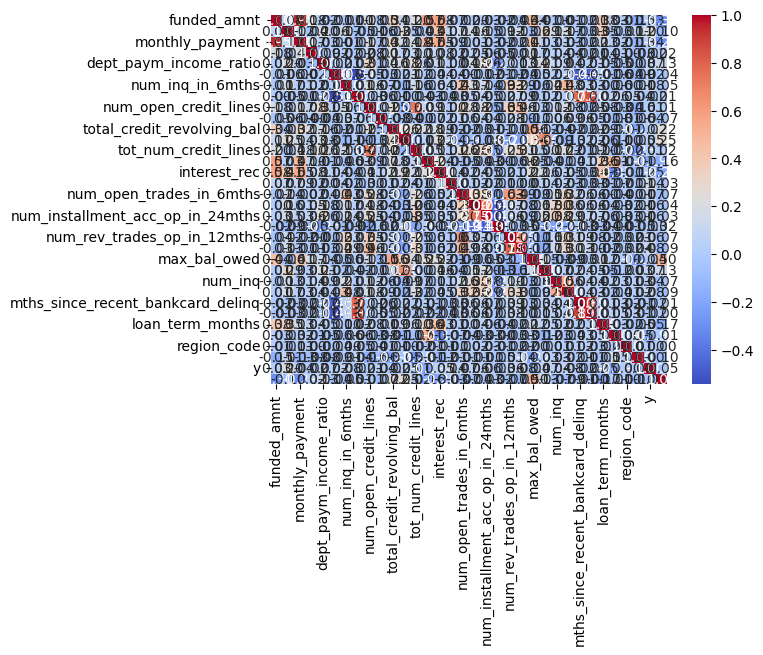

In [32]:
num_colsV2 = df.select_dtypes(include=np.number).columns.to_list()
corr  = df[num_colsV2].corr()

import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

In [33]:

corr = df.select_dtypes(include='number').corr(method='spearman').abs()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

pairs = (
    upper.stack()
    .reset_index()
)

pairs.columns = ['variable_1', 'variable_2', 'correlation']

print(
    pairs[pairs['correlation'] > 0.90]
    .sort_values('correlation', ascending=False)
    .to_string(index=False)
)

 variable_1      variable_2  correlation
funded_amnt monthly_payment     0.966093


In [34]:
df.groupby('home_ownership_status')['Loss'].agg(
    ['count', 'mean', 'median', 'std']
).sort_values('mean', ascending=False)

,count,mean,median,std
home_ownership_status,,,,
OTHER,985,47.711876,37.125000,42.420321
MORTGAGE,590367,47.197974,35.585000,43.416418
OWN,154393,45.944781,34.686275,43.113402
RENT,512250,44.628782,34.600668,40.482846


In [35]:

import numpy as np
import pandas as pd

state = (
    df['addr_state']
    .astype('string')
    .str.strip()
    .str.upper()
)

state_regions = {
    # Northeast
    'CT': 'Northeast', 'ME': 'Northeast',
    'MA': 'Northeast', 'NH': 'Northeast',
    'RI': 'Northeast', 'VT': 'Northeast',
    'NJ': 'Northeast', 'NY': 'Northeast',
    'PA': 'Northeast',

    # Midwest
    'IL': 'Midwest', 'IN': 'Midwest',
    'MI': 'Midwest', 'OH': 'Midwest',
    'WI': 'Midwest', 'IA': 'Midwest',
    'KS': 'Midwest', 'MN': 'Midwest',
    'MO': 'Midwest', 'NE': 'Midwest',
    'ND': 'Midwest', 'SD': 'Midwest',

    # South
    'DE': 'South', 'DC': 'South',
    'FL': 'South', 'GA': 'South',
    'MD': 'South', 'NC': 'South',
    'SC': 'South', 'VA': 'South',
    'WV': 'South', 'AL': 'South',
    'KY': 'South', 'MS': 'South',
    'TN': 'South', 'AR': 'South',
    'LA': 'South', 'OK': 'South',
    'TX': 'South',

    # West
    'AZ': 'West', 'CO': 'West',
    'ID': 'West', 'MT': 'West',
    'NV': 'West', 'NM': 'West',
    'UT': 'West', 'WY': 'West',
    'AK': 'West', 'CA': 'West',
    'HI': 'West', 'OR': 'West',
    'WA': 'West'
}

df['state_region'] = state.map(state_regions).fillna('Unknown')

# Distribución de las regiones
region_summary = (
    df['state_region']
    .value_counts()
    .rename_axis('state_region')
    .reset_index(name='count')
)

region_summary['percentage'] = (
    region_summary['count'] / len(df) * 100
).round(2)

print("DISTRIBUCIÓN POR REGIÓN")
print(region_summary.to_string(index=False))

# Revisar estados no reconocidos
print("\nESTADOS NO CLASIFICADOS")
print(
    df.loc[df['state_region'].eq('Unknown'), 'addr_state']
      .value_counts(dropna=False)
)


DISTRIBUCIÓN POR REGIÓN
state_region  count  percentage
       South 454702       36.14
        West 317939       25.27
   Northeast 261737       20.81
     Midwest 223617       17.78

ESTADOS NO CLASIFICADOS
Series([], Name: count, dtype: int64)


In [36]:
df['debt_capacity'] =  df['annual_income'] / df['funded_amnt']

In [37]:

import numpy as np
import pandas as pd

# Normalizar los valores
grade = (
    df['grade']
    .astype('string')
    .str.strip()
    .str.upper()
)

# Extraer letra y subgrado numérico
letter = grade.str.extract(r'^([A-G])', expand=False)
number = pd.to_numeric(
    grade.str.extract(r'^([A-G])([1-5])$', expand=True)[1],
    errors='coerce'
)

# Agrupar 1-3 como "+" y 4-5 como "-"
df['grade_group'] = np.select(
    [
        number.isin([1, 2, 3]),
        number.isin([4, 5])
    ],
    [
        letter + '+',
        letter + '-'
    ],
    default='Unknown'
)

# Resumen de distribución
grade_summary = (
    df['grade_group']
    .value_counts(dropna=False)
    .rename_axis('grade_group')
    .reset_index(name='count')
)

grade_summary['percentage'] = (
    grade_summary['count'] / len(df) * 100
).round(2)

print("DISTRIBUCIÓN DE GRADE_GROUP")
print(grade_summary.to_string(index=False))

print("\nVALIDACIÓN DE VALORES")
print(df[['grade', 'grade_group']].drop_duplicates().sort_values('grade'))


DISTRIBUCIÓN DE GRADE_GROUP
grade_group  count  percentage
         C+ 228867       18.19
         B+ 214637       17.06
         B- 162450       12.91
         A+ 148935       11.84
         C- 139673       11.10
         D+ 114682        9.12
         A- 114513        9.10
         D-  51903        4.13
         E+  37579        2.99
         E-  21485        1.71
         F+  12443        0.99
         F-   4786        0.38
         G+   4163        0.33
         G-   1879        0.15

VALIDACIÓN DE VALORES


      grade grade_group
32       A1          A+
216      A2          A+
222      A3          A+
11       A4          A-
85       A5          A-
42       B1          B+
39       B2          B+
10       B3          B+
24       B4          B-
13       B5          B-
0        C1          C+
8        C2          C+
34       C3          C+
4        C4          C-
71       C5          C-
2        D1          D+
1        D2          D+
26       D3          D+
15       D4          D-
9        D5          D-
19       E1          E+
303      E2          E+
103      E3          E+
20       E4          E-
151      E5          E-
19097    F1          F+
17406    F2          F+
46726    F3          F+
1496     F4          F-
36772    F5          F-
6110     G1          G+
8320     G2          G+
61255    G3          G+
60546    G4          G-
68275    G5          G-


In [38]:


df['grade_group_final'] = df['grade_group'].replace({
    'E+': 'EFG',
    'E-': 'EFG',
    'F+': 'EFG',
    'F-': 'EFG',
    'G+': 'EFG',
    'G-': 'EFG'
})

# Verificar distribución
grade_summary = (
    df['grade_group_final']
    .value_counts()
    .rename_axis('grade_group_final')
    .reset_index(name='count')
)

grade_summary['percentage'] = (
    grade_summary['count'] / len(df) * 100
).round(2)

print(grade_summary.to_string(index=False))


grade_group_final  count  percentage
               C+ 228867       18.19
               B+ 214637       17.06
               B- 162450       12.91
               A+ 148935       11.84
               C- 139673       11.10
               D+ 114682        9.12
               A- 114513        9.10
              EFG  82335        6.54
               D-  51903        4.13


In [39]:
df

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,home_ownership_status,annual_income,verification_status,addr_state,dept_paym_income_ratio,...,earliest_cr_line_year,y,Loss,employment_sector,loan_purpose_group,emp_length_group,state_region,debt_capacity,grade_group,grade_group_final
0,2500,13.56,84.92,C1,Chef,RENT,55000.0,Not Verified,NY,18.24,...,2001,0,85.480000,Hospitality & Food Service,Debt Consolidation,Long Tenure,Northeast,22.000000,C+,C+
1,30000,18.94,777.23,D2,Postmaster,MORTGAGE,90000.0,Source Verified,LA,26.52,...,1987,0,3.326667,Transportation & Logistics,Debt Consolidation,Long Tenure,South,3.000000,D+,D+
2,5000,17.97,180.69,D1,Administrative,MORTGAGE,59280.0,Source Verified,MI,10.51,...,2011,0,0.000000,Administration & HR,Debt Consolidation,Mid-Career,Midwest,11.856000,D+,D+
3,4000,18.94,146.51,D2,IT Supervisor,MORTGAGE,92000.0,Source Verified,WA,16.74,...,2006,0,94.025000,Technology & Engineering,Debt Consolidation,Long Tenure,West,23.000000,D+,D+
4,30000,16.14,731.78,C4,Mechanic,MORTGAGE,57250.0,Not Verified,MD,26.35,...,2000,0,1.720000,Industrial & Skilled Trades,Debt Consolidation,Long Tenure,South,1.908333,C-,C-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1257990,30000,30.75,984.47,F5,Sales,MORTGAGE,100000.0,Verified,FL,22.13,...,1996,0,31.860000,Sales & Marketing,Debt Consolidation,Mid-Career,South,3.333333,F-,EFG
1257991,12000,14.08,279.72,C3,house keeper,MORTGAGE,58000.0,Not Verified,VT,20.88,...,2004,0,33.766667,Hospitality & Food Service,Debt Consolidation,Long Tenure,Northeast,4.833333,C+,C+
1257992,10000,11.99,332.10,B5,Teacher,OWN,64000.0,Source Verified,IL,12.96,...,1995,0,18.640000,Education & Training,Debt Consolidation,Long Tenure,Midwest,6.400000,B-,B-
1257993,12000,21.45,327.69,D5,Unknown Employment Profile,RENT,60000.0,Not Verified,AK,30.82,...,2003,0,20.050000,Unknown Employment Profile,Debt Consolidation,Unknown Length Profile,West,5.000000,D-,D-


In [40]:
df.drop(columns=['grade'], inplace=True)
df.drop(columns=['emp_title'], inplace=True)
df.drop(columns=['addr_state'], inplace=True)
df.drop(columns=['grade_group'], inplace=True)

In [41]:
df

,funded_amnt,interest_rate,monthly_payment,home_ownership_status,annual_income,verification_status,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,...,earliest_cr_line_month,earliest_cr_line_year,y,Loss,employment_sector,loan_purpose_group,emp_length_group,state_region,debt_capacity,grade_group_final
0,2500,13.56,84.92,RENT,55000.0,Not Verified,18.24,0,1,NaN,...,Apr,2001,0,85.480000,Hospitality & Food Service,Debt Consolidation,Long Tenure,Northeast,22.000000,C+
1,30000,18.94,777.23,MORTGAGE,90000.0,Source Verified,26.52,0,0,71.0,...,Jun,1987,0,3.326667,Transportation & Logistics,Debt Consolidation,Long Tenure,South,3.000000,D+
2,5000,17.97,180.69,MORTGAGE,59280.0,Source Verified,10.51,0,0,NaN,...,Apr,2011,0,0.000000,Administration & HR,Debt Consolidation,Mid-Career,Midwest,11.856000,D+
3,4000,18.94,146.51,MORTGAGE,92000.0,Source Verified,16.74,0,0,NaN,...,Feb,2006,0,94.025000,Technology & Engineering,Debt Consolidation,Long Tenure,West,23.000000,D+
4,30000,16.14,731.78,MORTGAGE,57250.0,Not Verified,26.35,0,0,NaN,...,Dec,2000,0,1.720000,Industrial & Skilled Trades,Debt Consolidation,Long Tenure,South,1.908333,C-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1257990,30000,30.75,984.47,MORTGAGE,100000.0,Verified,22.13,0,2,NaN,...,Aug,1996,0,31.860000,Sales & Marketing,Debt Consolidation,Mid-Career,South,3.333333,EFG
1257991,12000,14.08,279.72,MORTGAGE,58000.0,Not Verified,20.88,0,0,NaN,...,Jan,2004,0,33.766667,Hospitality & Food Service,Debt Consolidation,Long Tenure,Northeast,4.833333,C+
1257992,10000,11.99,332.10,OWN,64000.0,Source Verified,12.96,0,0,NaN,...,Feb,1995,0,18.640000,Education & Training,Debt Consolidation,Long Tenure,Midwest,6.400000,B-
1257993,12000,21.45,327.69,RENT,60000.0,Not Verified,30.82,2,1,7.0,...,Jul,2003,0,20.050000,Unknown Employment Profile,Debt Consolidation,Unknown Length Profile,West,5.000000,D-


In [42]:
df = df.drop(columns=['earliest_cr_line_month'], errors='ignore')

In [43]:
df

,funded_amnt,interest_rate,monthly_payment,home_ownership_status,annual_income,verification_status,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,...,region_code,earliest_cr_line_year,y,Loss,employment_sector,loan_purpose_group,emp_length_group,state_region,debt_capacity,grade_group_final
0,2500,13.56,84.92,RENT,55000.0,Not Verified,18.24,0,1,NaN,...,1,2001,0,85.480000,Hospitality & Food Service,Debt Consolidation,Long Tenure,Northeast,22.000000,C+
1,30000,18.94,777.23,MORTGAGE,90000.0,Source Verified,26.52,0,0,71.0,...,7,1987,0,3.326667,Transportation & Logistics,Debt Consolidation,Long Tenure,South,3.000000,D+
2,5000,17.97,180.69,MORTGAGE,59280.0,Source Verified,10.51,0,0,NaN,...,4,2011,0,0.000000,Administration & HR,Debt Consolidation,Mid-Career,Midwest,11.856000,D+
3,4000,18.94,146.51,MORTGAGE,92000.0,Source Verified,16.74,0,0,NaN,...,9,2006,0,94.025000,Technology & Engineering,Debt Consolidation,Long Tenure,West,23.000000,D+
4,30000,16.14,731.78,MORTGAGE,57250.0,Not Verified,26.35,0,0,NaN,...,2,2000,0,1.720000,Industrial & Skilled Trades,Debt Consolidation,Long Tenure,South,1.908333,C-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1257990,30000,30.75,984.47,MORTGAGE,100000.0,Verified,22.13,0,2,NaN,...,3,1996,0,31.860000,Sales & Marketing,Debt Consolidation,Mid-Career,South,3.333333,EFG
1257991,12000,14.08,279.72,MORTGAGE,58000.0,Not Verified,20.88,0,0,NaN,...,0,2004,0,33.766667,Hospitality & Food Service,Debt Consolidation,Long Tenure,Northeast,4.833333,C+
1257992,10000,11.99,332.10,OWN,64000.0,Source Verified,12.96,0,0,NaN,...,6,1995,0,18.640000,Education & Training,Debt Consolidation,Long Tenure,Midwest,6.400000,B-
1257993,12000,21.45,327.69,RENT,60000.0,Not Verified,30.82,2,1,7.0,...,9,2003,0,20.050000,Unknown Employment Profile,Debt Consolidation,Unknown Length Profile,West,5.000000,D-


In [44]:
drop_cols = [
    'emp_title',
    'region_code',
    'issue_date_month',
    'earliest_cr_line_month',
    'princ_rec',
    'paym_rec_for_tot_amnt_fund',
    'interest_rec',
    'late_fees_rec'
]

df = df.drop(columns=drop_cols, errors='ignore')

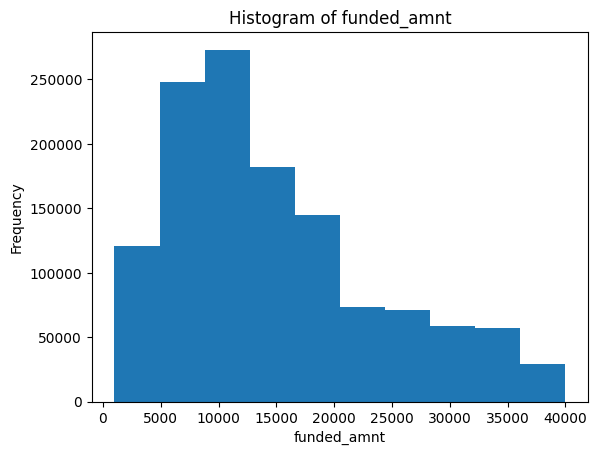

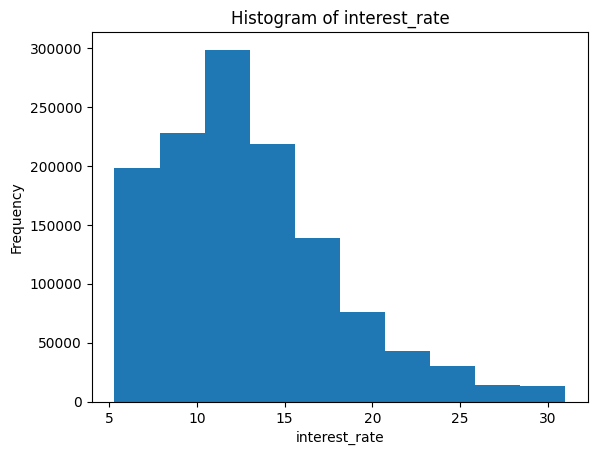

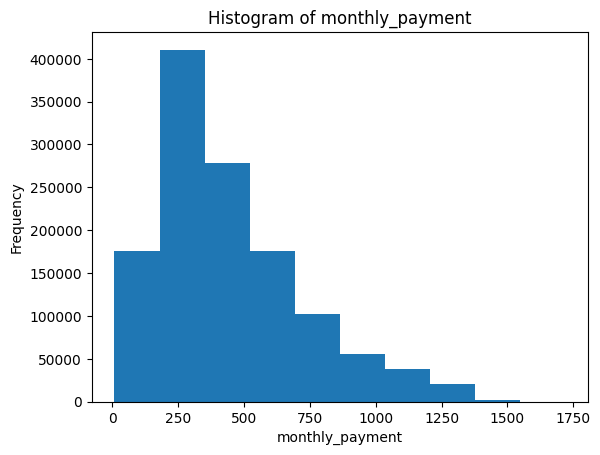

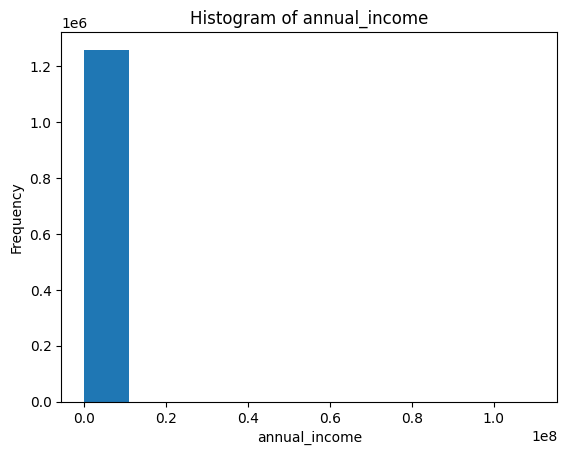

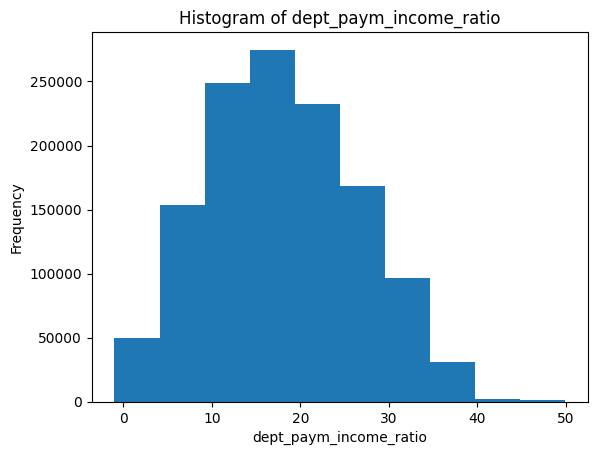

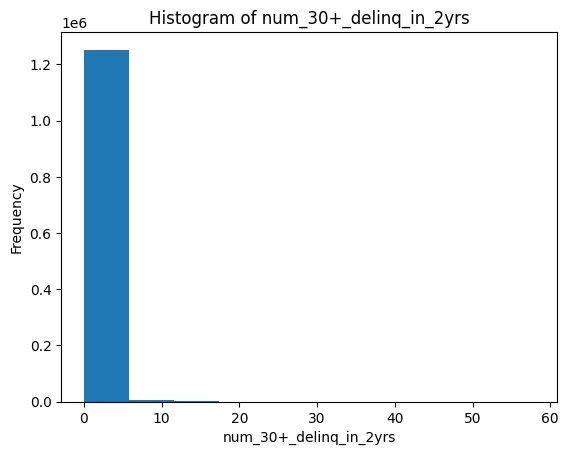

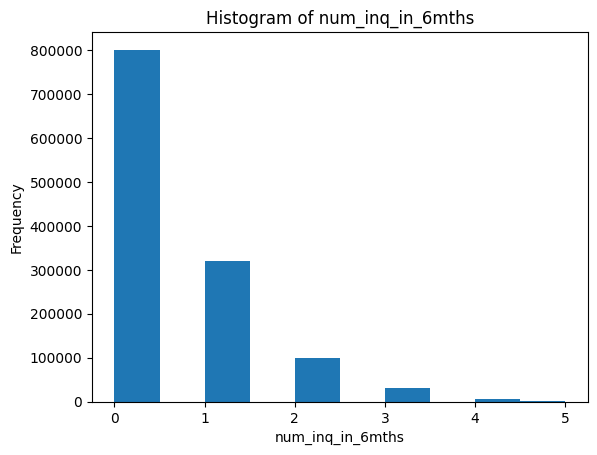

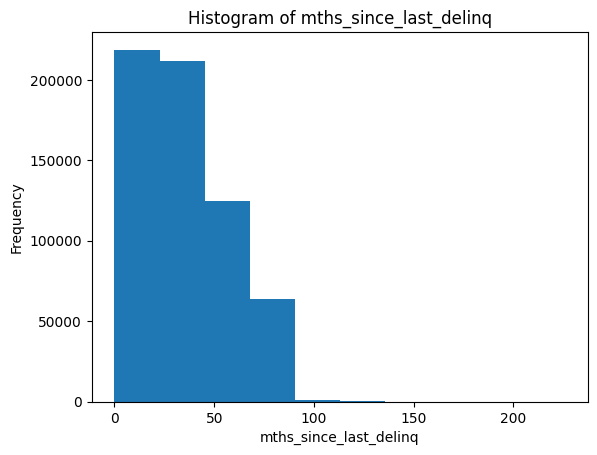

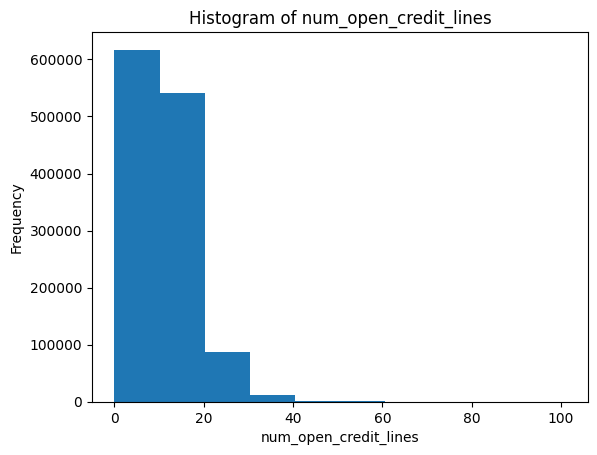

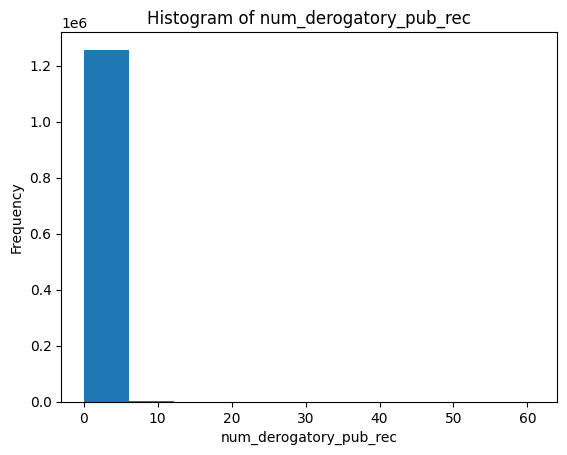

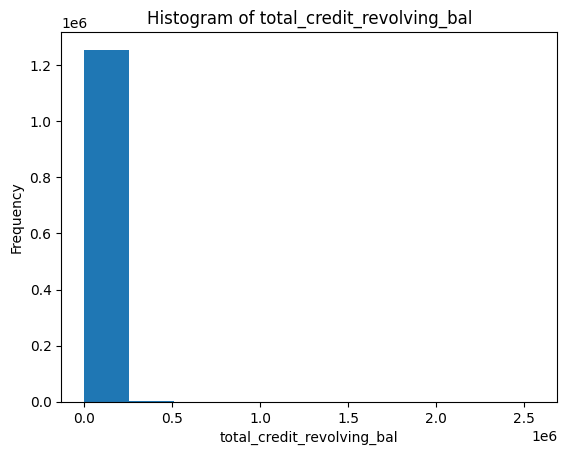

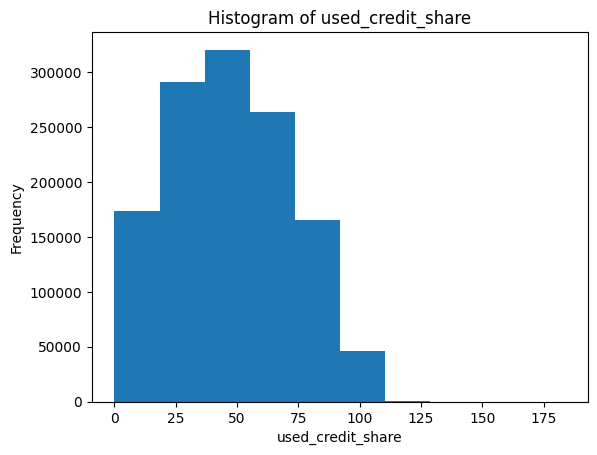

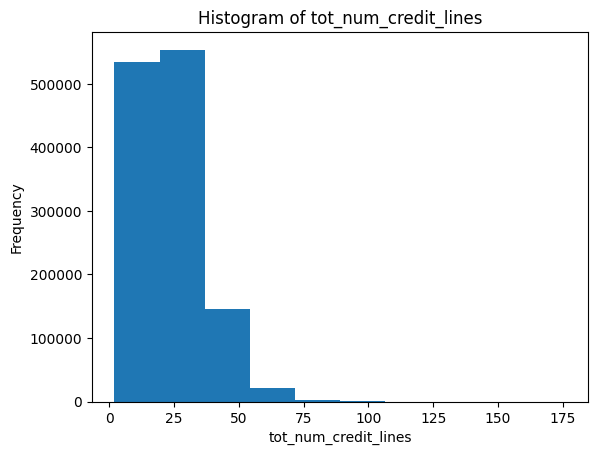

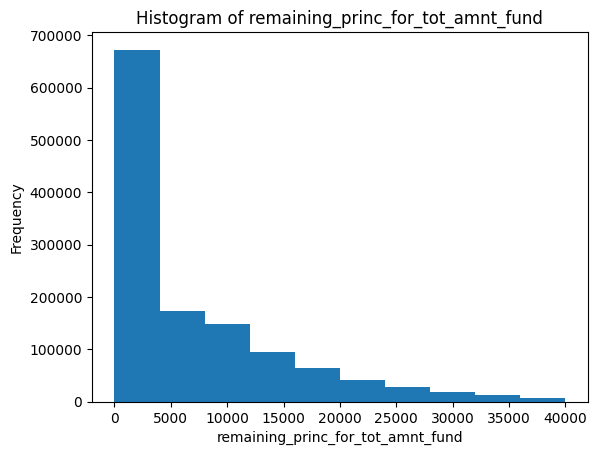

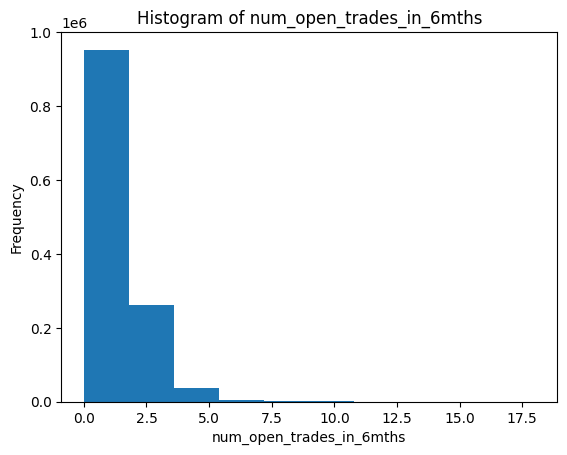

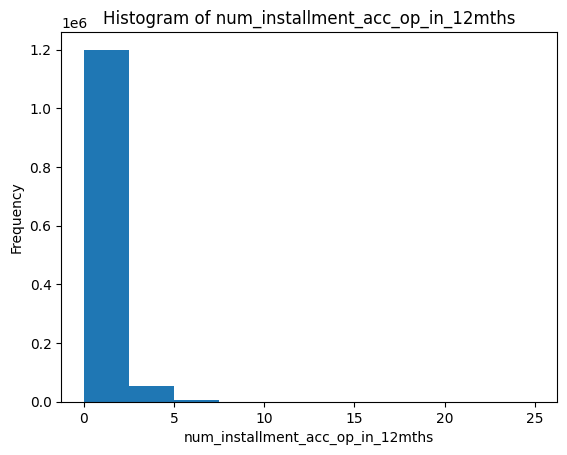

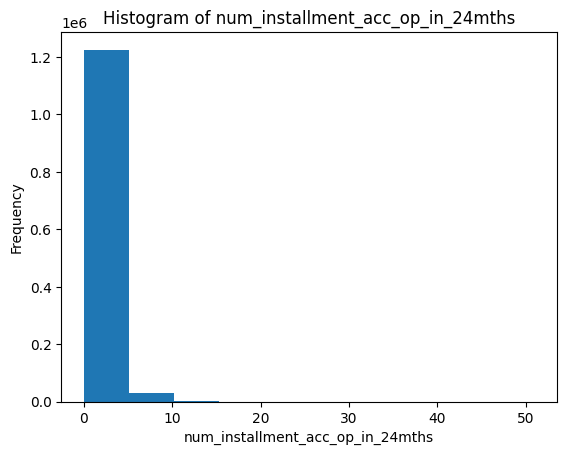

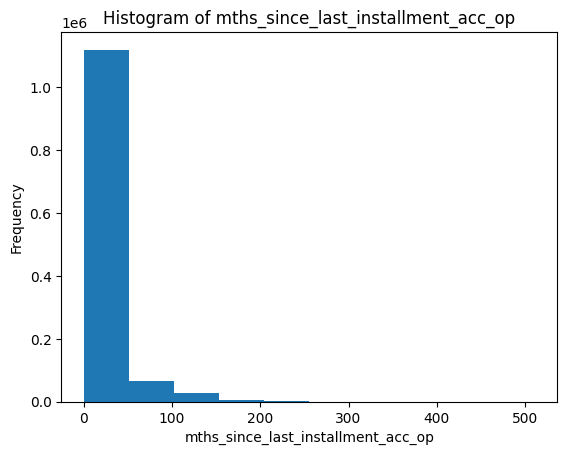

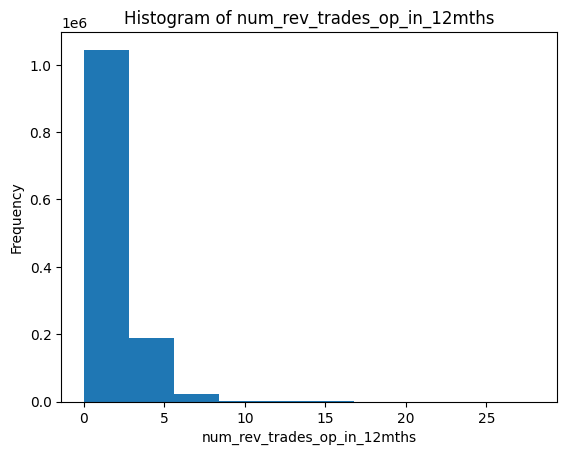

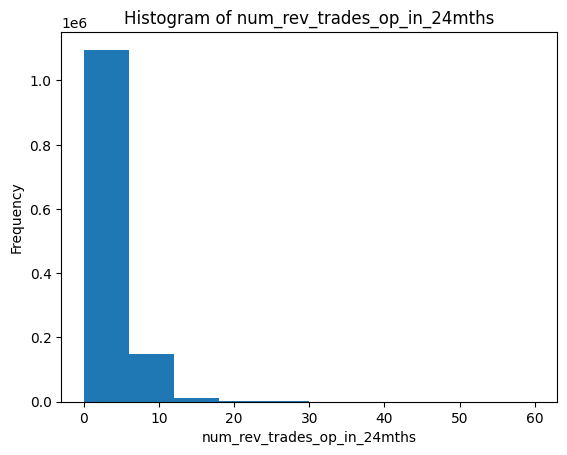

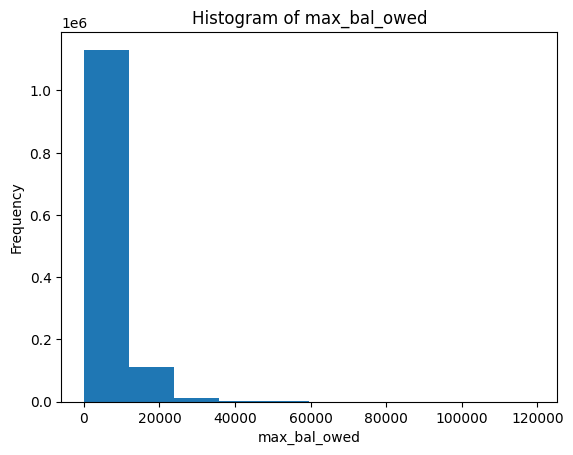

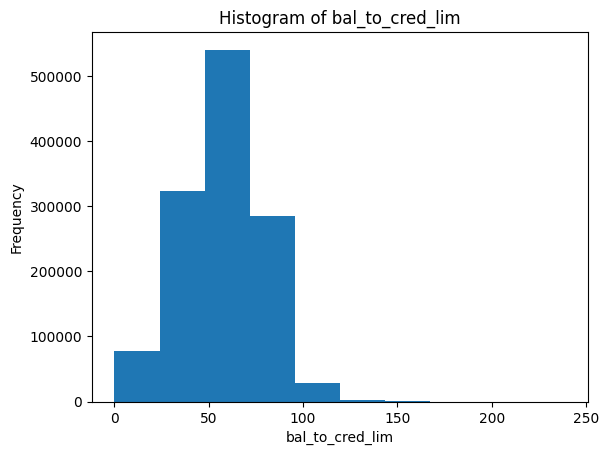

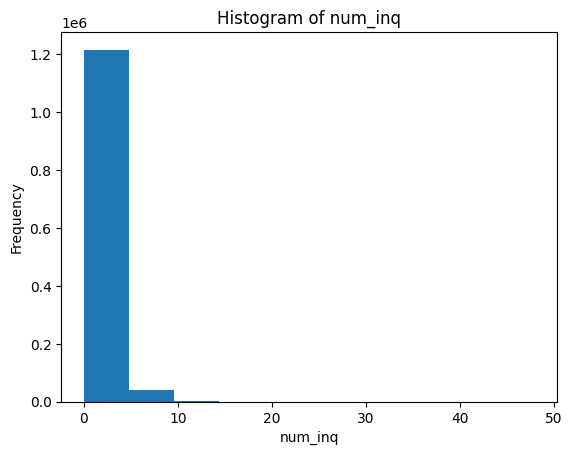

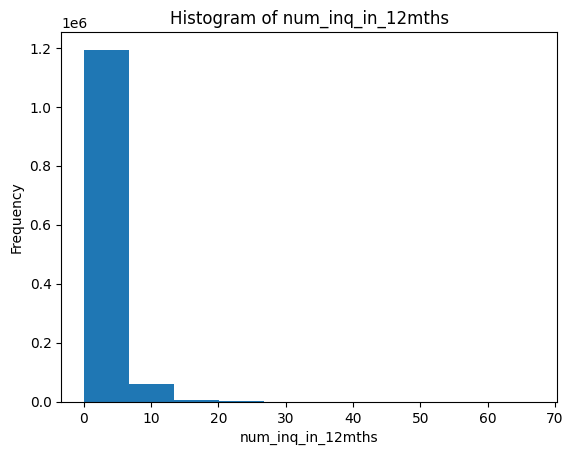

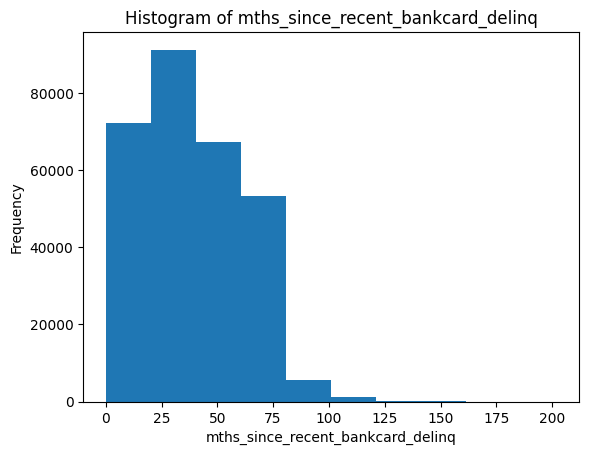

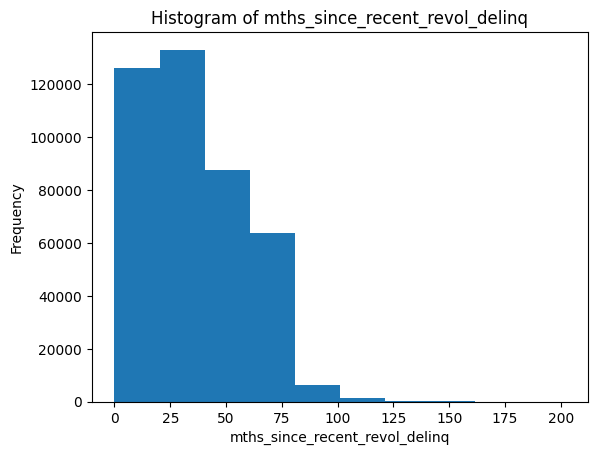

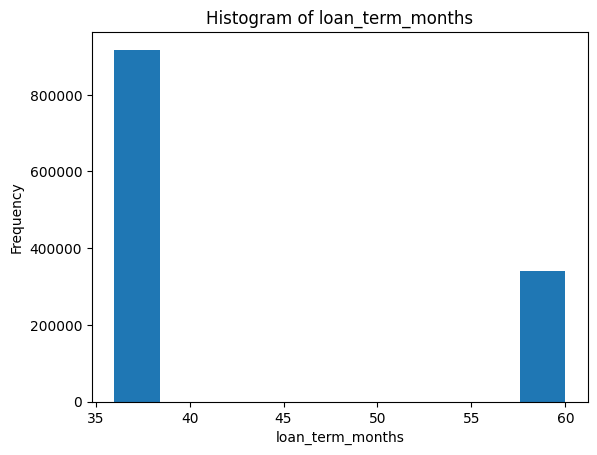

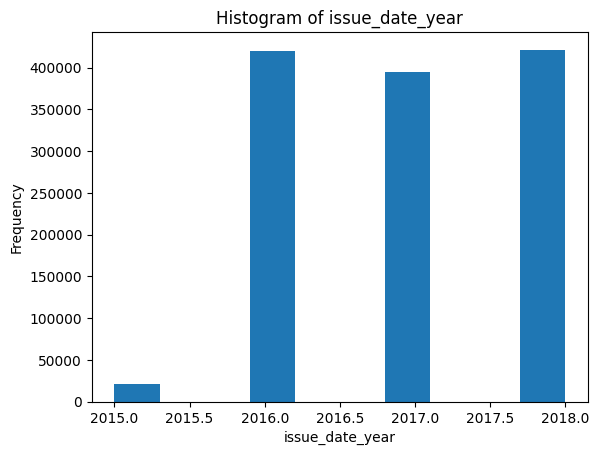

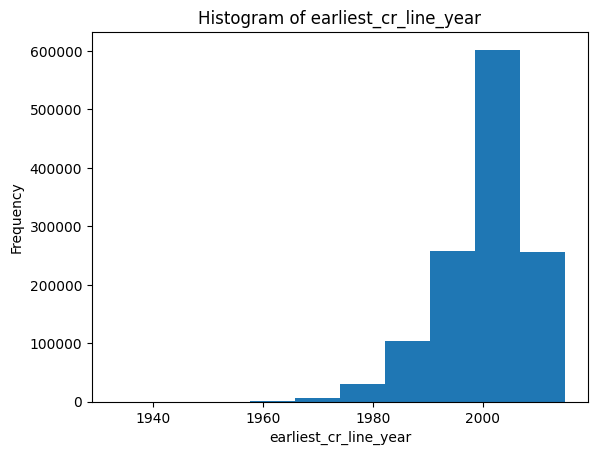

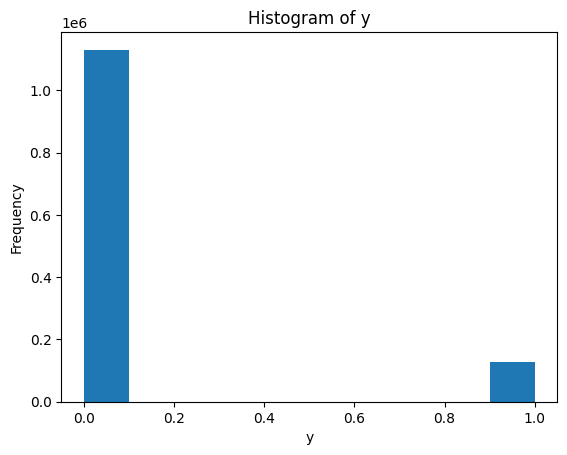

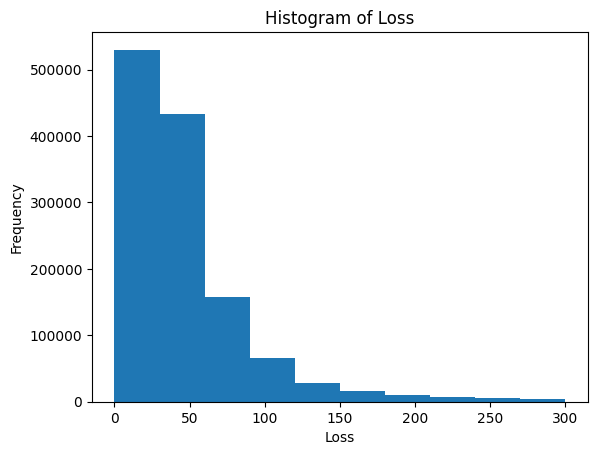

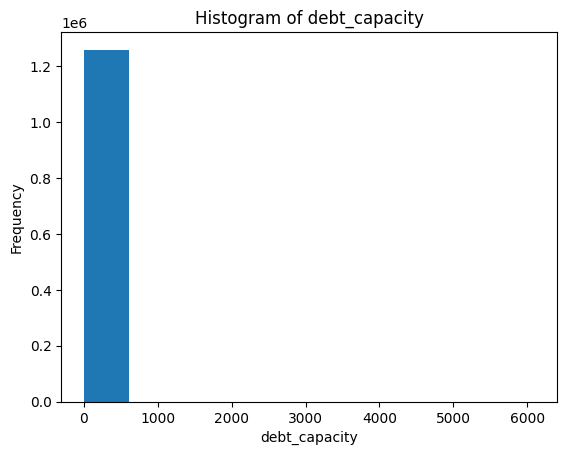

In [45]:
NumColsV = df.select_dtypes(include=np.number).columns.tolist()

for  i in NumColsV:
    plt.hist(df[i])
    plt.title(f'Histogram of {i}')
    plt.xlabel(i)
    plt.ylabel('Frequency')
    plt.show()

In [46]:
from sklearn.metrics import roc_auc_score

def auditar(df, cols, target='y'):
    out = []
    for c in cols:
        s = df[c]; m = s.notna()
        auc = roc_auc_score(df.loc[m, target], s[m]) if s[m].nunique() > 1 else np.nan
        out.append({'col': c,
                    'pct_null': 100 * s.isna().mean(),                                   # ¿muchos nulos?
                    'top_pct': 100 * s.value_counts(normalize=True, dropna=False).iloc[0],  # ¿casi constante?
                    'corr_y': s.corr(df[target]),
                    'auc_solo': max(auc, 1 - auc)})                                      # ~0.5 = sin señal; muy alto = sospechoso
    return pd.DataFrame(out).set_index('col').sort_values('auc_solo', ascending=False)

auditar(df, [c for c in NumColsV if c != 'y'])

# Redundancia: pares con |corr| > 0.8
cm = df[NumColsV].corr().abs()
cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack().loc[lambda s: s > 0.8]


funded_amnt                        monthly_payment                   0.946621
mths_since_last_delinq             mths_since_recent_revol_delinq    0.861324
mths_since_recent_bankcard_delinq  mths_since_recent_revol_delinq    0.889871
dtype: float64

In [47]:
leakage = ['remaining_princ_for_tot_amnt_fund', 'princ_rec', 'paym_rec_for_tot_amnt_fund',
           'interest_rec', 'late_fees_rec']
redundantes = ['monthly_payment', 'mths_since_recent_bankcard_delinq', 'mths_since_recent_revol_delinq']
sin_senal = ['region_code']

df['credit_age'] = df['issue_date_year'] - df['earliest_cr_line_year']
df['had_delinq'] = df['mths_since_last_delinq'].notna().astype(int)

num_cols_modelo = [c for c in num_cols
                   if c not in leakage + redundantes + sin_senal + ['y', 'issue_date_year', 'earliest_cr_line_year']]


In [48]:
df = df.drop(columns=leakage + sin_senal, errors='ignore')

# Check: this should print an empty list
print([c for c in leakage + sin_senal if c in df.columns])


[]


In [49]:
df

,funded_amnt,interest_rate,monthly_payment,home_ownership_status,annual_income,verification_status,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,...,y,Loss,employment_sector,loan_purpose_group,emp_length_group,state_region,debt_capacity,grade_group_final,credit_age,had_delinq
0,2500,13.56,84.92,RENT,55000.0,Not Verified,18.24,0,1,NaN,...,0,85.480000,Hospitality & Food Service,Debt Consolidation,Long Tenure,Northeast,22.000000,C+,17,0
1,30000,18.94,777.23,MORTGAGE,90000.0,Source Verified,26.52,0,0,71.0,...,0,3.326667,Transportation & Logistics,Debt Consolidation,Long Tenure,South,3.000000,D+,31,1
2,5000,17.97,180.69,MORTGAGE,59280.0,Source Verified,10.51,0,0,NaN,...,0,0.000000,Administration & HR,Debt Consolidation,Mid-Career,Midwest,11.856000,D+,7,0
3,4000,18.94,146.51,MORTGAGE,92000.0,Source Verified,16.74,0,0,NaN,...,0,94.025000,Technology & Engineering,Debt Consolidation,Long Tenure,West,23.000000,D+,12,0
4,30000,16.14,731.78,MORTGAGE,57250.0,Not Verified,26.35,0,0,NaN,...,0,1.720000,Industrial & Skilled Trades,Debt Consolidation,Long Tenure,South,1.908333,C-,18,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1257990,30000,30.75,984.47,MORTGAGE,100000.0,Verified,22.13,0,2,NaN,...,0,31.860000,Sales & Marketing,Debt Consolidation,Mid-Career,South,3.333333,EFG,21,0
1257991,12000,14.08,279.72,MORTGAGE,58000.0,Not Verified,20.88,0,0,NaN,...,0,33.766667,Hospitality & Food Service,Debt Consolidation,Long Tenure,Northeast,4.833333,C+,13,0
1257992,10000,11.99,332.10,OWN,64000.0,Source Verified,12.96,0,0,NaN,...,0,18.640000,Education & Training,Debt Consolidation,Long Tenure,Midwest,6.400000,B-,22,0
1257993,12000,21.45,327.69,RENT,60000.0,Not Verified,30.82,2,1,7.0,...,0,20.050000,Unknown Employment Profile,Debt Consolidation,Unknown Length Profile,West,5.000000,D-,14,1


In [50]:
df['payment_to_income'] = df['monthly_payment'] / (df['annual_income'] / 12)
df = df.drop(columns=['monthly_payment'])


In [51]:
df = df.drop(columns=['mths_since_recent_bankcard_delinq', 'mths_since_recent_revol_delinq'], errors='ignore')


In [52]:
df

,funded_amnt,interest_rate,home_ownership_status,annual_income,verification_status,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,num_open_credit_lines,...,Loss,employment_sector,loan_purpose_group,emp_length_group,state_region,debt_capacity,grade_group_final,credit_age,had_delinq,payment_to_income
0,2500,13.56,RENT,55000.0,Not Verified,18.24,0,1,NaN,9,...,85.480000,Hospitality & Food Service,Debt Consolidation,Long Tenure,Northeast,22.000000,C+,17,0,0.018528
1,30000,18.94,MORTGAGE,90000.0,Source Verified,26.52,0,0,71.0,13,...,3.326667,Transportation & Logistics,Debt Consolidation,Long Tenure,South,3.000000,D+,31,1,0.103631
2,5000,17.97,MORTGAGE,59280.0,Source Verified,10.51,0,0,NaN,8,...,0.000000,Administration & HR,Debt Consolidation,Mid-Career,Midwest,11.856000,D+,7,0,0.036577
3,4000,18.94,MORTGAGE,92000.0,Source Verified,16.74,0,0,NaN,10,...,94.025000,Technology & Engineering,Debt Consolidation,Long Tenure,West,23.000000,D+,12,0,0.019110
4,30000,16.14,MORTGAGE,57250.0,Not Verified,26.35,0,0,NaN,12,...,1.720000,Industrial & Skilled Trades,Debt Consolidation,Long Tenure,South,1.908333,C-,18,0,0.153386
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1257990,30000,30.75,MORTGAGE,100000.0,Verified,22.13,0,2,NaN,9,...,31.860000,Sales & Marketing,Debt Consolidation,Mid-Career,South,3.333333,EFG,21,0,0.118136
1257991,12000,14.08,MORTGAGE,58000.0,Not Verified,20.88,0,0,NaN,12,...,33.766667,Hospitality & Food Service,Debt Consolidation,Long Tenure,Northeast,4.833333,C+,13,0,0.057873
1257992,10000,11.99,OWN,64000.0,Source Verified,12.96,0,0,NaN,6,...,18.640000,Education & Training,Debt Consolidation,Long Tenure,Midwest,6.400000,B-,22,0,0.062269
1257993,12000,21.45,RENT,60000.0,Not Verified,30.82,2,1,7.0,8,...,20.050000,Unknown Employment Profile,Debt Consolidation,Unknown Length Profile,West,5.000000,D-,14,1,0.065538


In [53]:
df = df.drop(columns=['mths_since_last_delinq'], errors='ignore')

In [54]:
df


,funded_amnt,interest_rate,home_ownership_status,annual_income,verification_status,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,num_open_credit_lines,num_derogatory_pub_rec,...,Loss,employment_sector,loan_purpose_group,emp_length_group,state_region,debt_capacity,grade_group_final,credit_age,had_delinq,payment_to_income
0,2500,13.56,RENT,55000.0,Not Verified,18.24,0,1,9,1,...,85.480000,Hospitality & Food Service,Debt Consolidation,Long Tenure,Northeast,22.000000,C+,17,0,0.018528
1,30000,18.94,MORTGAGE,90000.0,Source Verified,26.52,0,0,13,1,...,3.326667,Transportation & Logistics,Debt Consolidation,Long Tenure,South,3.000000,D+,31,1,0.103631
2,5000,17.97,MORTGAGE,59280.0,Source Verified,10.51,0,0,8,0,...,0.000000,Administration & HR,Debt Consolidation,Mid-Career,Midwest,11.856000,D+,7,0,0.036577
3,4000,18.94,MORTGAGE,92000.0,Source Verified,16.74,0,0,10,0,...,94.025000,Technology & Engineering,Debt Consolidation,Long Tenure,West,23.000000,D+,12,0,0.019110
4,30000,16.14,MORTGAGE,57250.0,Not Verified,26.35,0,0,12,0,...,1.720000,Industrial & Skilled Trades,Debt Consolidation,Long Tenure,South,1.908333,C-,18,0,0.153386
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1257990,30000,30.75,MORTGAGE,100000.0,Verified,22.13,0,2,9,0,...,31.860000,Sales & Marketing,Debt Consolidation,Mid-Career,South,3.333333,EFG,21,0,0.118136
1257991,12000,14.08,MORTGAGE,58000.0,Not Verified,20.88,0,0,12,0,...,33.766667,Hospitality & Food Service,Debt Consolidation,Long Tenure,Northeast,4.833333,C+,13,0,0.057873
1257992,10000,11.99,OWN,64000.0,Source Verified,12.96,0,0,6,0,...,18.640000,Education & Training,Debt Consolidation,Long Tenure,Midwest,6.400000,B-,22,0,0.062269
1257993,12000,21.45,RENT,60000.0,Not Verified,30.82,2,1,8,0,...,20.050000,Unknown Employment Profile,Debt Consolidation,Unknown Length Profile,West,5.000000,D-,14,1,0.065538


In [55]:
num_cols_modelo = df.select_dtypes(include=np.number).columns.tolist()
df[num_cols_modelo].isnull().sum()

funded_amnt                               0
interest_rate                             0
annual_income                             0
dept_paym_income_ratio                    0
num_30+_delinq_in_2yrs                    0
num_inq_in_6mths                          0
num_open_credit_lines                     0
num_derogatory_pub_rec                    0
total_credit_revolving_bal                0
used_credit_share                         0
tot_num_credit_lines                      0
num_open_trades_in_6mths                  0
num_installment_acc_op_in_12mths          0
num_installment_acc_op_in_24mths          0
mths_since_last_installment_acc_op    39251
num_rev_trades_op_in_12mths               0
num_rev_trades_op_in_24mths               0
max_bal_owed                              0
bal_to_cred_lim                         119
num_inq                                   0
num_inq_in_12mths                         0
loan_term_months                          0
issue_date_year                 

In [56]:

col = 'mths_since_last_installment_acc_op'

print('Nulos (%):', df[col].isna().mean() * 100)
print('Valores únicos:', df[col].nunique())
print(df[col].describe())

col = 'mths_since_last_installment_acc_op'

# Crear indicador de valores faltantes
df[f'{col}_missing'] = df[col].isna().astype(int)

# Imputar con la mediana
df[col] = df[col].fillna(df[col].median())


Nulos (%): 3.1201236888858856
Valores únicos: 402
count    1.218744e+06
mean     2.114666e+01
std      2.598106e+01
min      0.000000e+00
25%      7.000000e+00
50%      1.300000e+01
75%      2.400000e+01
max      5.110000e+02
Name: mths_since_last_installment_acc_op, dtype: float64


In [57]:
col = 'bal_to_cred_lim'

df[f'{col}_missing'] = df[col].isna().astype(int)
df[col] = df[col].fillna(df[col].median())

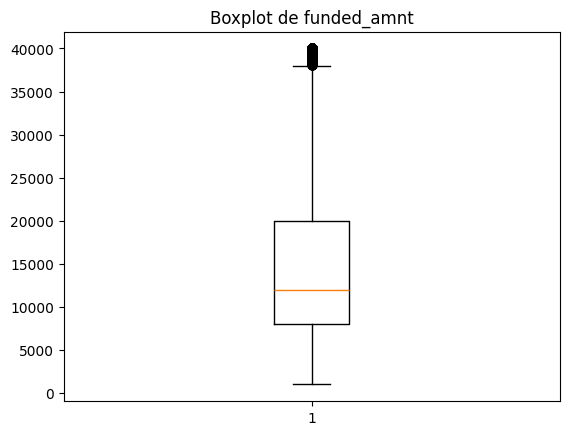

Estadísticas de funded_amnt:
count    1.257995e+06
mean     1.496395e+04
std      9.387214e+03
min      1.000000e+03
25%      8.000000e+03
50%      1.200000e+04
75%      2.000000e+04
max      4.000000e+04
Name: funded_amnt, dtype: float64




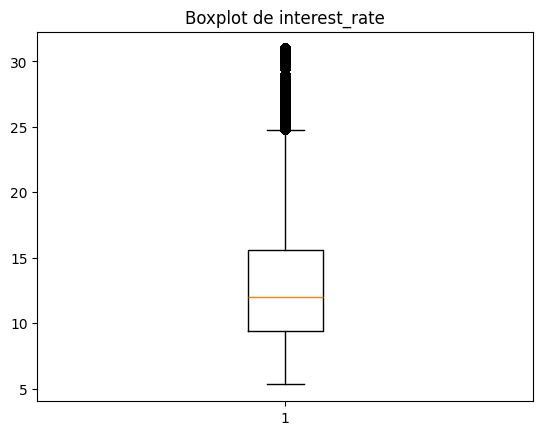

Estadísticas de interest_rate:
count    1.257995e+06
mean     1.291378e+01
std      5.055656e+00
min      5.310000e+00
25%      9.430000e+00
50%      1.199000e+01
75%      1.559000e+01
max      3.099000e+01
Name: interest_rate, dtype: float64




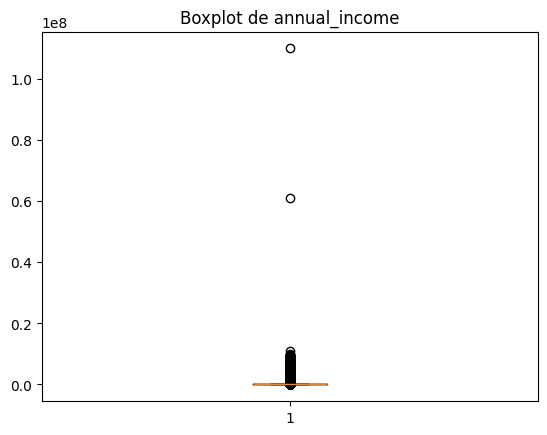

Estadísticas de annual_income:
count    1.257995e+06
mean     8.164390e+04
std      1.394705e+05
min      1.900000e+03
25%      4.800000e+04
50%      6.825000e+04
75%      9.769750e+04
max      1.100000e+08
Name: annual_income, dtype: float64




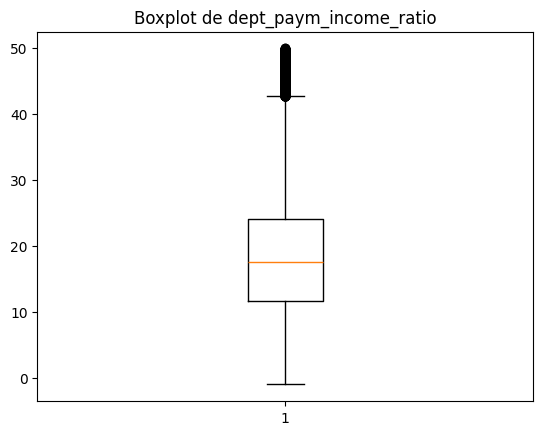

Estadísticas de dept_paym_income_ratio:


count    1.257995e+06
mean     1.804731e+01
std      8.514294e+00
min     -1.000000e+00
25%      1.166000e+01
50%      1.753000e+01
75%      2.408000e+01
max      4.996000e+01
Name: dept_paym_income_ratio, dtype: float64




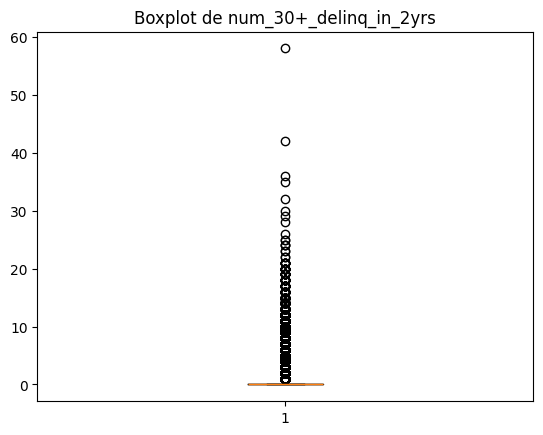

Estadísticas de num_30+_delinq_in_2yrs:
count    1.257995e+06
mean     3.082715e-01
std      8.817419e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      5.800000e+01
Name: num_30+_delinq_in_2yrs, dtype: float64




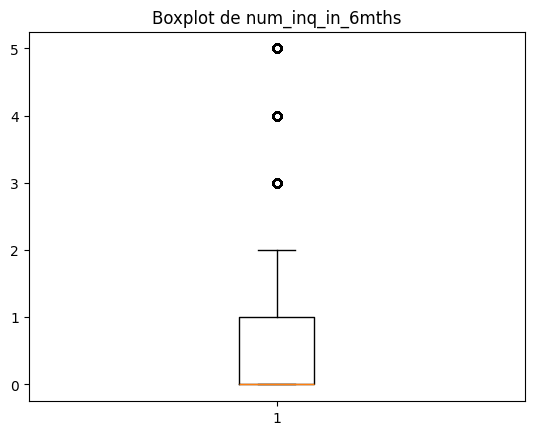

Estadísticas de num_inq_in_6mths:
count    1.257995e+06
mean     5.137373e-01
std      8.067567e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      1.000000e+00
max      5.000000e+00
Name: num_inq_in_6mths, dtype: float64




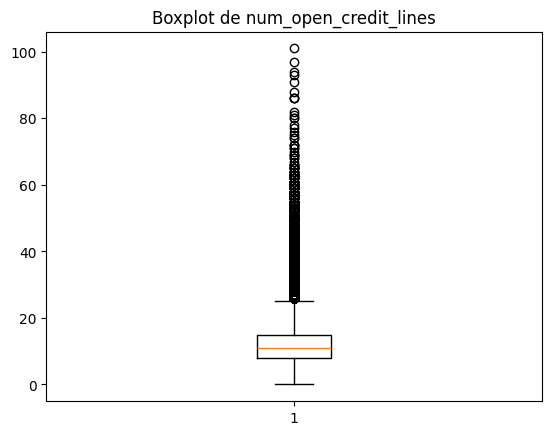

Estadísticas de num_open_credit_lines:
count    1.257995e+06
mean     1.171547e+01
std      5.866348e+00
min      0.000000e+00
25%      8.000000e+00
50%      1.100000e+01
75%      1.500000e+01
max      1.010000e+02
Name: num_open_credit_lines, dtype: float64




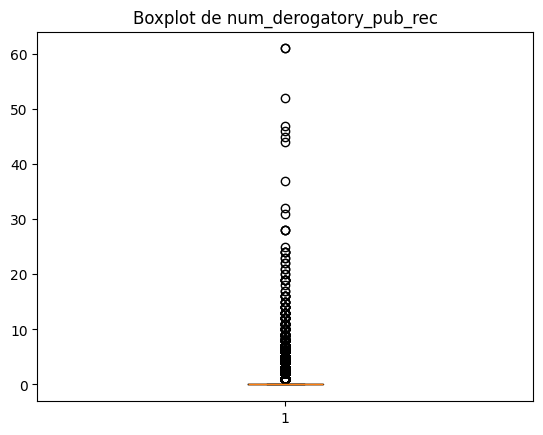

Estadísticas de num_derogatory_pub_rec:
count    1.257995e+06
mean     2.053188e-01
std      5.773825e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      6.100000e+01
Name: num_derogatory_pub_rec, dtype: float64




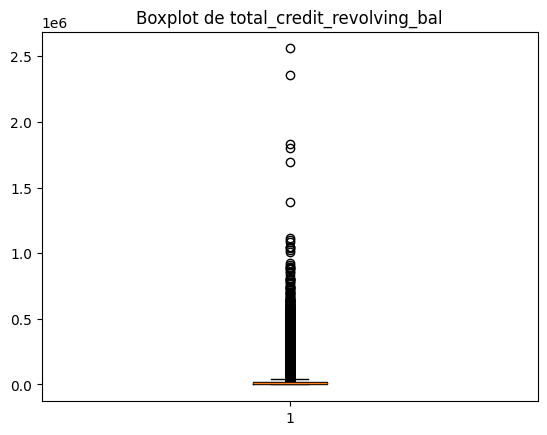

Estadísticas de total_credit_revolving_bal:
count    1.257995e+06
mean     1.628896e+04
std      2.291988e+04
min      0.000000e+00
25%      5.622000e+03
50%      1.085600e+04
75%      1.956400e+04
max      2.559552e+06
Name: total_credit_revolving_bal, dtype: float64




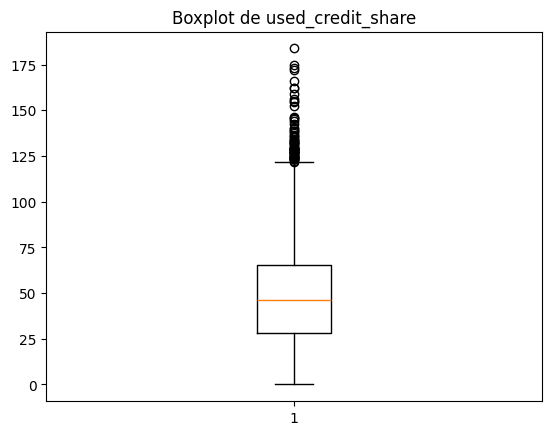

Estadísticas de used_credit_share:


count    1.257995e+06
mean     4.709317e+01
std      2.461551e+01
min      0.000000e+00
25%      2.800000e+01
50%      4.610000e+01
75%      6.550000e+01
max      1.838000e+02
Name: used_credit_share, dtype: float64




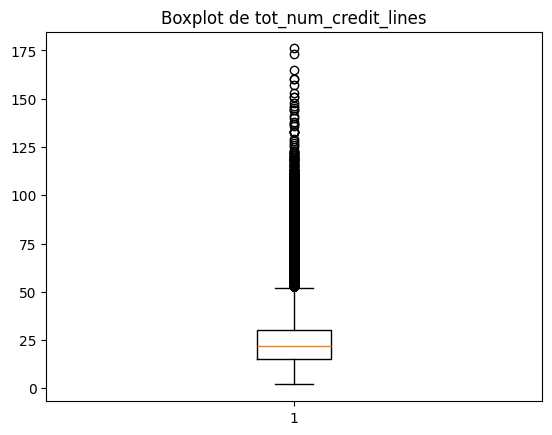

Estadísticas de tot_num_credit_lines:


count    1.257995e+06
mean     2.355231e+01
std      1.208640e+01
min      2.000000e+00
25%      1.500000e+01
50%      2.200000e+01
75%      3.000000e+01
max      1.760000e+02
Name: tot_num_credit_lines, dtype: float64




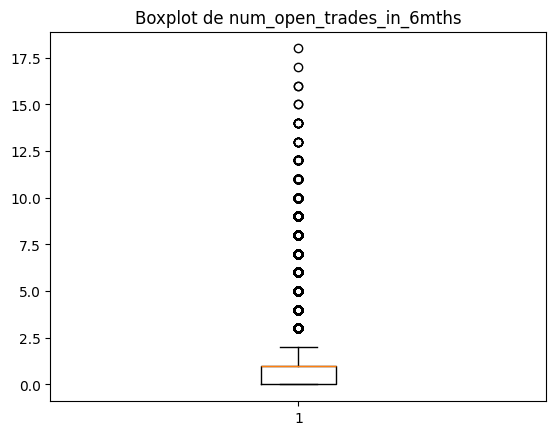

Estadísticas de num_open_trades_in_6mths:
count    1.257995e+06
mean     9.457041e-01
std      1.149261e+00
min      0.000000e+00
25%      0.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.800000e+01
Name: num_open_trades_in_6mths, dtype: float64




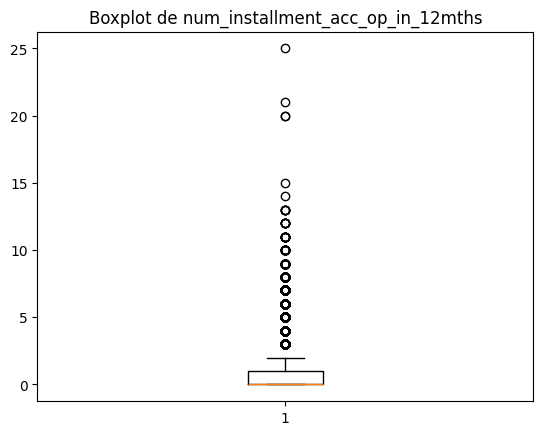

Estadísticas de num_installment_acc_op_in_12mths:
count    1.257995e+06
mean     6.778556e-01
std      9.272282e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      1.000000e+00
max      2.500000e+01
Name: num_installment_acc_op_in_12mths, dtype: float64




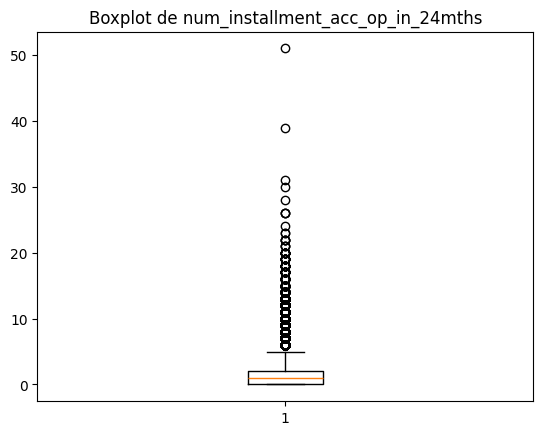

Estadísticas de num_installment_acc_op_in_24mths:
count    1.257995e+06
mean     1.567758e+00
std      1.581562e+00
min      0.000000e+00
25%      0.000000e+00
50%      1.000000e+00
75%      2.000000e+00
max      5.100000e+01
Name: num_installment_acc_op_in_24mths, dtype: float64




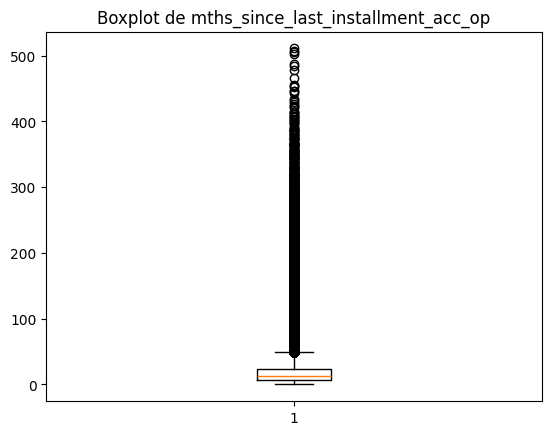

Estadísticas de mths_since_last_installment_acc_op:
count    1.257995e+06
mean     2.089247e+01
std      2.561173e+01
min      0.000000e+00
25%      7.000000e+00
50%      1.300000e+01
75%      2.400000e+01
max      5.110000e+02
Name: mths_since_last_installment_acc_op, dtype: float64




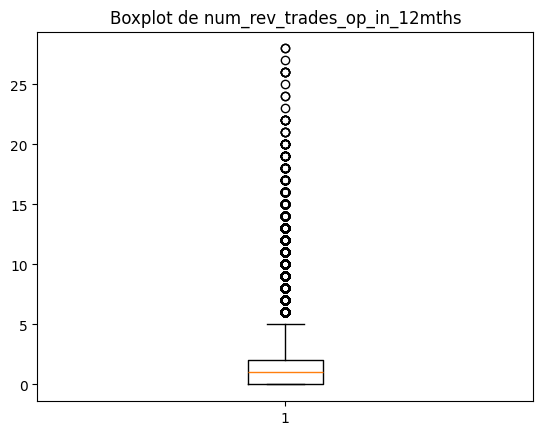

Estadísticas de num_rev_trades_op_in_12mths:
count    1.257995e+06
mean     1.318068e+00
std      1.524751e+00
min      0.000000e+00
25%      0.000000e+00
50%      1.000000e+00
75%      2.000000e+00
max      2.800000e+01
Name: num_rev_trades_op_in_12mths, dtype: float64




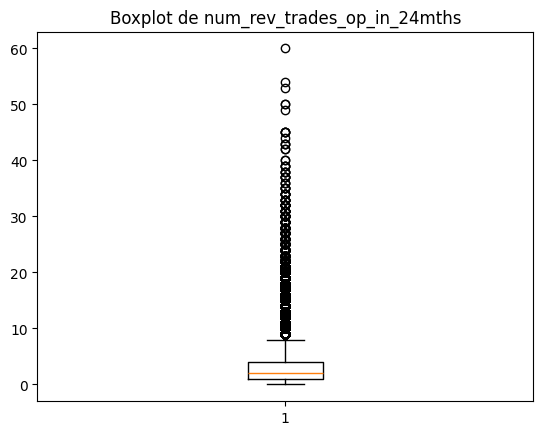

Estadísticas de num_rev_trades_op_in_24mths:
count    1.257995e+06
mean     2.805575e+00
std      2.627012e+00
min      0.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      4.000000e+00
max      6.000000e+01
Name: num_rev_trades_op_in_24mths, dtype: float64




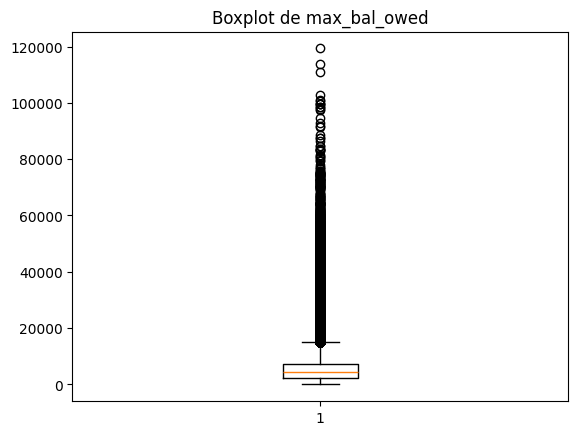

Estadísticas de max_bal_owed:
count    1.257995e+06
mean     5.685166e+03
std      5.187538e+03
min      0.000000e+00
25%      2.275000e+03
50%      4.354000e+03
75%      7.445000e+03
max      1.193040e+05
Name: max_bal_owed, dtype: float64




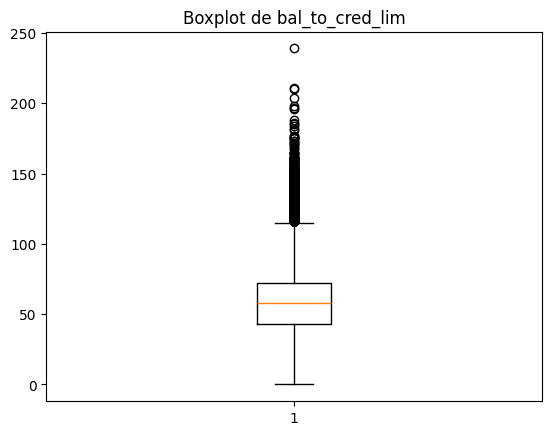

Estadísticas de bal_to_cred_lim:


count    1.257995e+06
mean     5.695111e+01
std      2.085168e+01
min      0.000000e+00
25%      4.300000e+01
50%      5.800000e+01
75%      7.200000e+01
max      2.390000e+02
Name: bal_to_cred_lim, dtype: float64




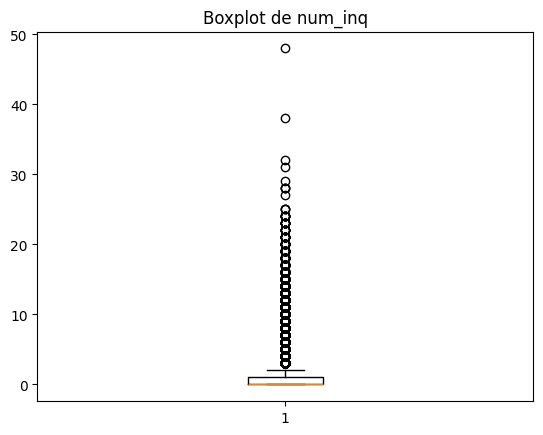

Estadísticas de num_inq:
count    1.257995e+06
mean     1.009959e+00
std      1.487672e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      1.000000e+00
max      4.800000e+01
Name: num_inq, dtype: float64




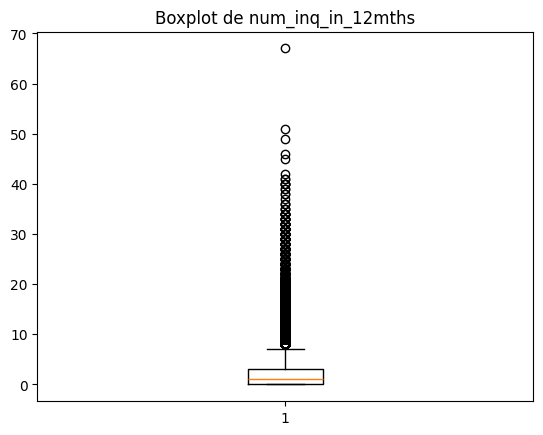

Estadísticas de num_inq_in_12mths:
count    1.257995e+06
mean     2.045220e+00
std      2.379623e+00
min      0.000000e+00
25%      0.000000e+00
50%      1.000000e+00
75%      3.000000e+00
max      6.700000e+01
Name: num_inq_in_12mths, dtype: float64




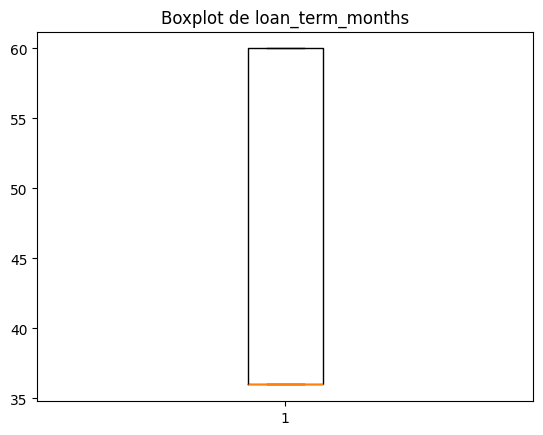

Estadísticas de loan_term_months:
count    1.257995e+06
mean     4.248920e+01
std      1.065979e+01
min      3.600000e+01
25%      3.600000e+01
50%      3.600000e+01
75%      6.000000e+01
max      6.000000e+01
Name: loan_term_months, dtype: float64




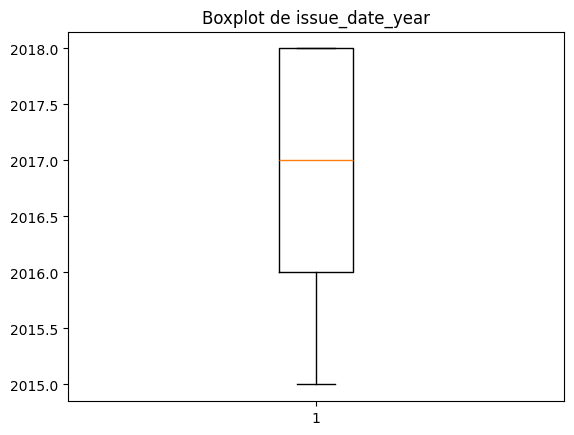

Estadísticas de issue_date_year:
count    1.257995e+06
mean     2.016968e+03
std      8.571728e-01
min      2.015000e+03
25%      2.016000e+03
50%      2.017000e+03
75%      2.018000e+03
max      2.018000e+03
Name: issue_date_year, dtype: float64




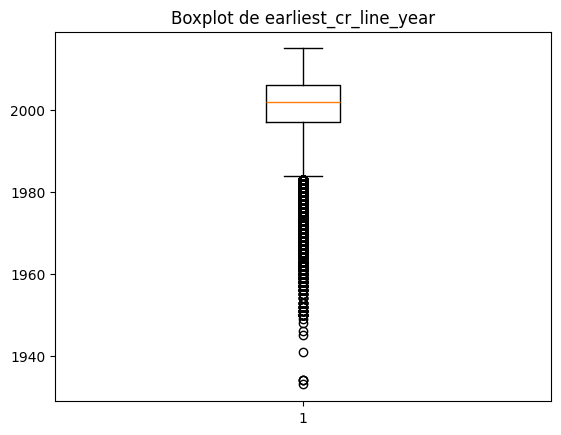

Estadísticas de earliest_cr_line_year:
count    1.257995e+06
mean     2.000607e+03
std      7.869298e+00
min      1.933000e+03
25%      1.997000e+03
50%      2.002000e+03
75%      2.006000e+03
max      2.015000e+03
Name: earliest_cr_line_year, dtype: float64




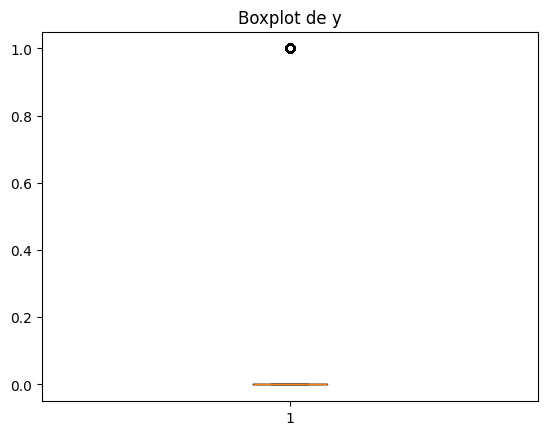

Estadísticas de y:
count    1.257995e+06
mean     1.017309e-01
std      3.022943e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.000000e+00
Name: y, dtype: float64




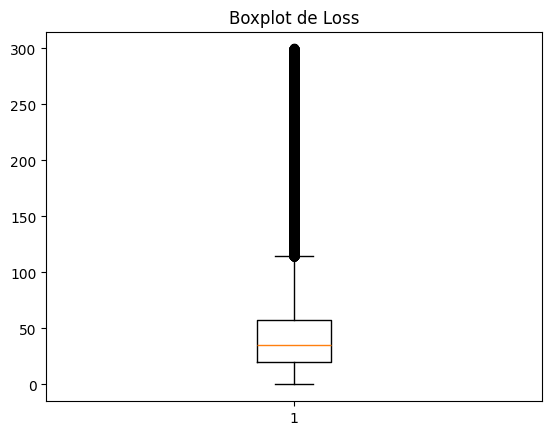

Estadísticas de Loss:
count    1.257995e+06
mean     4.599841e+01
std      4.222460e+01
min      0.000000e+00
25%      1.970000e+01
50%      3.506000e+01
75%      5.785000e+01
max      2.999800e+02
Name: Loss, dtype: float64




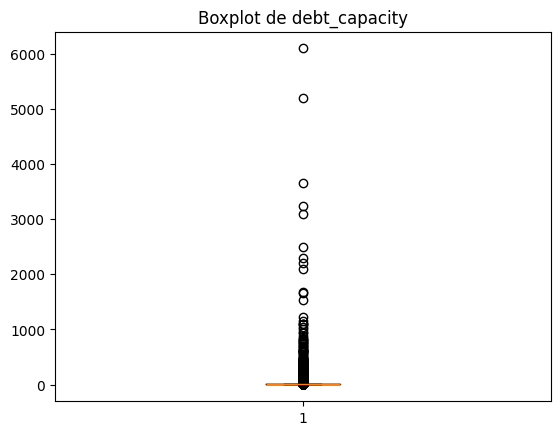

Estadísticas de debt_capacity:
count    1.257995e+06
mean     7.400880e+00
std      1.324307e+01
min      7.237636e-01
25%      3.571429e+00
50%      5.272500e+00
75%      8.375000e+00
max      6.100000e+03
Name: debt_capacity, dtype: float64




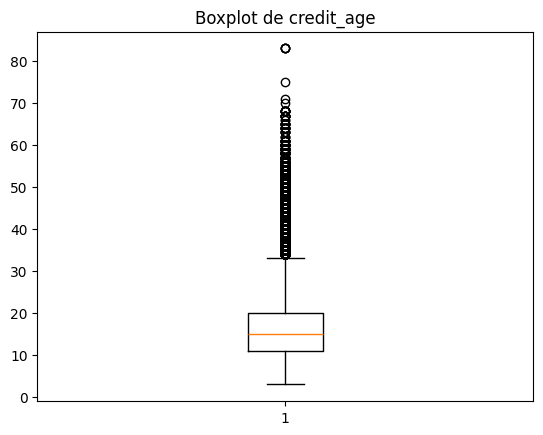

Estadísticas de credit_age:
count    1.257995e+06
mean     1.636107e+01
std      7.791287e+00
min      3.000000e+00
25%      1.100000e+01
50%      1.500000e+01
75%      2.000000e+01
max      8.300000e+01
Name: credit_age, dtype: float64




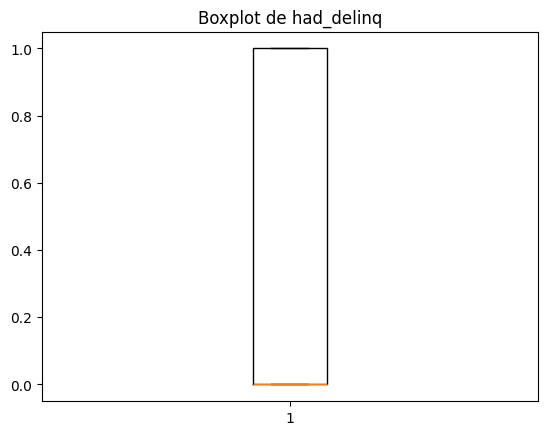

Estadísticas de had_delinq:
count    1.257995e+06
mean     4.930179e-01
std      4.999514e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: had_delinq, dtype: float64




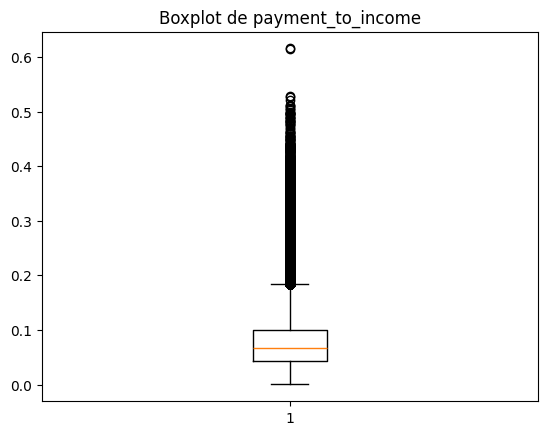

Estadísticas de payment_to_income:
count    1.257995e+06
mean     7.605147e-02
std      4.409163e-02
min      6.481574e-05
25%      4.353143e-02
50%      6.760571e-02
75%      9.974311e-02
max      6.155040e-01
Name: payment_to_income, dtype: float64




In [58]:
for col in num_cols_modelo:
    plt.boxplot(df[col])
    plt.title(f'Boxplot de {col}')
    plt.show()
    print(f'Estadísticas de {col}:')
    print(df[col].describe())
    print('\n')

In [59]:
df[num_cols_modelo]

,funded_amnt,interest_rate,annual_income,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,...,num_inq_in_12mths,loan_term_months,issue_date_year,earliest_cr_line_year,y,Loss,debt_capacity,credit_age,had_delinq,payment_to_income
0,2500,13.56,55000.0,18.24,0,1,9,1,4341,10.3,...,2,36,2018,2001,0,85.480000,22.000000,17,0,0.018528
1,30000,18.94,90000.0,26.52,0,0,13,1,12315,24.2,...,2,60,2018,1987,0,3.326667,3.000000,31,1,0.103631
2,5000,17.97,59280.0,10.51,0,0,8,0,4599,19.1,...,0,36,2018,2011,0,0.000000,11.856000,7,0,0.036577
3,4000,18.94,92000.0,16.74,0,0,10,0,5468,78.1,...,3,36,2018,2006,0,94.025000,23.000000,12,0,0.019110
4,30000,16.14,57250.0,26.35,0,0,12,0,829,3.6,...,0,60,2018,2000,0,1.720000,1.908333,18,0,0.153386
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1257990,30000,30.75,100000.0,22.13,0,2,9,0,19206,66.9,...,3,60,2017,1996,0,31.860000,3.333333,21,0,0.118136
1257991,12000,14.08,58000.0,20.88,0,0,12,0,9592,39.2,...,1,60,2017,2004,0,33.766667,4.833333,13,0,0.057873
1257992,10000,11.99,64000.0,12.96,0,0,6,0,7094,70.9,...,3,36,2017,1995,0,18.640000,6.400000,22,0,0.062269
1257993,12000,21.45,60000.0,30.82,2,1,8,0,12927,34.9,...,4,60,2017,2003,0,20.050000,5.000000,14,1,0.065538


In [60]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns='y'), df['y'], test_size=0.2, stratify=df['y'], random_state=42)

log_cols = ['annual_income', 'mths_since_last_installment_acc_op', 'num_inq_in_12mths',
            'num_rev_trades_op_in_12mths', 'num_rev_trades_op_in_24mths',
            'num_installment_acc_op_in_24mths', 'num_open_trades_in_6mths']
clip_cols = ['total_credit_revolving_bal', 'max_bal_owed', 'used_credit_share',
             'bal_to_cred_lim', 'num_inq_in_6mths', 'num_inq'] + log_cols
bin_cols = ['num_derogatory_pub_rec', 'num_30+_delinq_in_2yrs']

# Percentiles calculados SOLO con train, para no filtrar información del test
p01 = X_train[clip_cols].quantile(0.01)
p99 = X_train[clip_cols].quantile(0.99)

for X in (X_train, X_test):
    X['dept_paym_income_ratio'] = X['dept_paym_income_ratio'].where(X['dept_paym_income_ratio'] >= 0)
    X[clip_cols] = X[clip_cols].clip(lower=p01, upper=p99, axis=1)
    X[log_cols] = np.log1p(X[log_cols])
    for c in bin_cols:
        X[c] = (X[c] > 0).astype(int)


In [61]:
cats_cols_modelo = df.select_dtypes(include=object).columns
cats_cols_modelo

C:\Users\Diego Monegro\AppData\Local\Temp\ipykernel_21480\620188686.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cats_cols_modelo = df.select_dtypes(include=object).columns


Index(['home_ownership_status', 'verification_status', 'initial_list_status',
       'disbursement_method', 'employment_sector', 'loan_purpose_group',
       'emp_length_group', 'state_region', 'grade_group_final'],
      dtype='str')

In [62]:
df = df.drop(columns=['issue_date_year', 'earliest_cr_line_year'], errors='ignore')


In [63]:
df['no_installment_acc'] = df['mths_since_last_installment_acc_op'].isna().astype(int)
df['mths_since_last_installment_acc_op'] = df['mths_since_last_installment_acc_op'].fillna(999)


In [64]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report

cat_cols = X_train.select_dtypes(include=['object', 'string']).columns.tolist()
num_cols = X_train.select_dtypes(include='number').columns.tolist()
print('Categóricas:', cat_cols)

prep = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)),
                      ('sc', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
], sparse_threshold=0)

modelos = {
    'Logística': LogisticRegression(class_weight='balanced', max_iter=1000),
    'HistGB':    HistGradientBoostingClassifier(class_weight='balanced', random_state=42),
}

for nombre, clf in modelos.items():
    pipe = Pipeline([('prep', prep), ('clf', clf)])
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    print(f'\n===== {nombre} =====')
    print('ROC-AUC:', round(roc_auc_score(y_test, proba), 4))
    print('PR-AUC :', round(average_precision_score(y_test, proba), 4), ' (azar ≈ 0.10)')
    print(classification_report(y_test, (proba >= 0.5).astype(int), digits=3))



Categóricas: ['home_ownership_status', 'verification_status', 'initial_list_status', 'disbursement_method', 'employment_sector', 'loan_purpose_group', 'emp_length_group', 'state_region', 'grade_group_final']



===== Logística =====
ROC-AUC: 0.7688
PR-AUC : 0.271  (azar ≈ 0.10)


              precision    recall  f1-score   support

           0      0.955     0.677     0.792    226004
           1      0.201     0.719     0.315     25595

    accuracy                          0.681    251599
   macro avg      0.578     0.698     0.553    251599
weighted avg      0.878     0.681     0.744    251599




===== HistGB =====
ROC-AUC: 0.7791
PR-AUC : 0.2841  (azar ≈ 0.10)


              precision    recall  f1-score   support

           0      0.959     0.664     0.784    226004
           1      0.201     0.748     0.317     25595

    accuracy                          0.672    251599
   macro avg      0.580     0.706     0.551    251599
weighted avg      0.882     0.672     0.737    251599



In [65]:
%pip install xgboost


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\Diego Monegro\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [66]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report, confusion_matrix

# 1. XGBoost acepta categóricas directamente si son tipo 'category' (no hace falta one-hot)
cat_cols = X_train.select_dtypes(include=['object', 'string']).columns.tolist()
for X in (X_train, X_test):
    X[cat_cols] = X[cat_cols].astype('category')

# 2. Validación separada del train para el early stopping (el test no se toca hasta el final)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=42)

# 3. Peso de la clase 1 por el desbalance (~9 ceros por cada 1)
peso = (y_tr == 0).sum() / (y_tr == 1).sum()
print('scale_pos_weight:', round(peso, 2))

modelo_xgb = xgb.XGBClassifier(
    n_estimators=2000,          # tope alto; el early stopping decide cuándo parar
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=50,        # evita hojas con muy pocos casos
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    scale_pos_weight=peso,
    tree_method='hist',         # rápido con 1M de filas
    enable_categorical=True,
    eval_metric='aucpr',
    early_stopping_rounds=100,
    n_jobs=-1,
    random_state=42,
)

modelo_xgb.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=100)
print('Mejor iteración:', modelo_xgb.best_iteration)

# 4. Métricas en test
proba = modelo_xgb.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print('\nROC-AUC:', round(roc_auc_score(y_test, proba), 4))
print('PR-AUC :', round(average_precision_score(y_test, proba), 4), ' (azar ≈ 0.10)')
print(classification_report(y_test, pred, digits=3))
print(confusion_matrix(y_test, pred))


scale_pos_weight: 8.83


[0]	validation_0-aucpr:0.24667


[100]	validation_0-aucpr:0.27583


[200]	validation_0-aucpr:0.27936


[300]	validation_0-aucpr:0.28076


...

[600]	validation_0-aucpr:0.28138


[635]	validation_0-aucpr:0.28140


Mejor iteración: 535



ROC-AUC: 0.7822
PR-AUC : 0.2877  (azar ≈ 0.10)
              precision    recall  f1-score   support

           0      0.958     0.679     0.795    226004
           1      0.207     0.739     0.323     25595

    accuracy                          0.685    251599
   macro avg      0.582     0.709     0.559    251599
weighted avg      0.882     0.685     0.747    251599



[[153372  72632]
 [  6690  18905]]


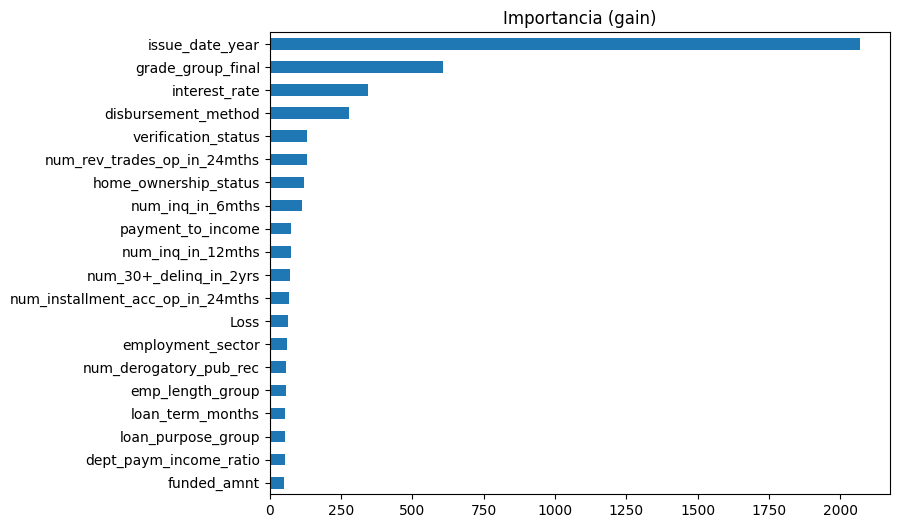

In [67]:
imp = pd.Series(modelo_xgb.get_booster().get_score(importance_type='gain')).sort_values()
imp.tail(20).plot(kind='barh', figsize=(8, 6), title='Importancia (gain)')
plt.show()


In [68]:
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (proba >= t).astype(int)
    print(t, classification_report(y_test, p, output_dict=True)['1'])


0.3 {'precision': 0.15536713873193578, 'recall': 0.9228364915022466, 'f1-score': 0.26595804573757753, 'support': 25595.0}
0.4 {'precision': 0.17765059355660423, 'recall': 0.8501269779253761, 'f1-score': 0.2938876395388886, 'support': 25595.0}


0.5 {'precision': 0.20652850759802047, 'recall': 0.7386208243797616, 'f1-score': 0.32279821056585734, 'support': 25595.0}
0.6 {'precision': 0.24616170268845547, 'recall': 0.5838249658136355, 'f1-score': 0.34630760495486623, 'support': 25595.0}


0.7 {'precision': 0.3026796402590626, 'recall': 0.3852705606563782, 'f1-score': 0.33901743046721905, 'support': 25595.0}


In [69]:

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, uniform, loguniform

# Muestra de 200k filas para que la búsqueda sea rápida
X_s = X_train.sample(200_000, random_state=42)
y_s = y_train.loc[X_s.index]

peso = (y_s == 0).sum() / (y_s == 1).sum()

base = xgb.XGBClassifier(
    n_estimators=400,           # fijo durante la búsqueda (sin early stopping)
    tree_method='hist',
    enable_categorical=True,
    scale_pos_weight=peso,
    eval_metric='aucpr',
    n_jobs=-1,
    random_state=42,
)

param_dist = {
    'max_depth':        randint(3, 10),
    'learning_rate':    loguniform(0.02, 0.2),
    'min_child_weight': randint(1, 200),
    'subsample':        uniform(0.6, 0.4),     # entre 0.6 y 1.0
    'colsample_bytree': uniform(0.5, 0.5),     # entre 0.5 y 1.0
    'reg_lambda':       loguniform(0.1, 20),
    'gamma':            uniform(0, 5),
}

busqueda = RandomizedSearchCV(
    base, param_dist,
    n_iter=25,
    scoring='average_precision',   # PR-AUC: la mejor métrica con clases desbalanceadas
    cv=StratifiedKFold(3, shuffle=True, random_state=42),
    n_jobs=1,                      # XGBoost ya usa todos los núcleos
    verbose=2,
    random_state=42,
)
busqueda.fit(X_s, y_s)

print('Mejor PR-AUC (CV):', round(busqueda.best_score_, 4))
print('Mejores parámetros:', busqueda.best_params_)

pd.DataFrame(busqueda.cv_results_).sort_values('rank_test_score')[
    ['params', 'mean_test_score', 'std_test_score']].head(10)


Fitting 3 folds for each of 25 candidates, totalling 75 fits


[CV] END colsample_bytree=0.6872700594236812, gamma=4.75357153204958, learning_rate=0.10790061933340454, max_depth=7, min_child_weight=21, reg_lambda=0.22856175997064762, subsample=0.662397808134481; total time=  10.8s


[CV] END colsample_bytree=0.6872700594236812, gamma=4.75357153204958, learning_rate=0.10790061933340454, max_depth=7, min_child_weight=21, reg_lambda=0.22856175997064762, subsample=0.662397808134481; total time=   9.8s


[CV] END colsample_bytree=0.6872700594236812, gamma=4.75357153204958, learning_rate=0.10790061933340454, max_depth=7, min_child_weight=21, reg_lambda=0.22856175997064762, subsample=0.662397808134481; total time=   9.0s


[CV] END colsample_bytree=0.5290418060840998, gamma=4.330880728874676, learning_rate=0.0798261175712336, max_depth=5, min_child_weight=150, reg_lambda=0.1348356507325798, subsample=0.8887995089067299; total time=   6.7s


...

[CV] END colsample_bytree=0.7447263801387816, gamma=4.928252270553004, learning_rate=0.034920887064667006, max_depth=6, min_child_weight=183, reg_lambda=5.656002335993311, subsample=0.6950550175969599; total time=   6.5s


[CV] END colsample_bytree=0.7447263801387816, gamma=4.928252270553004, learning_rate=0.034920887064667006, max_depth=6, min_child_weight=183, reg_lambda=5.656002335993311, subsample=0.6950550175969599; total time=   6.2s


[CV] END colsample_bytree=0.7447263801387816, gamma=4.928252270553004, learning_rate=0.034920887064667006, max_depth=6, min_child_weight=183, reg_lambda=5.656002335993311, subsample=0.6950550175969599; total time=   6.0s


Mejor PR-AUC (CV): 0.2748
Mejores parámetros: {'colsample_bytree': np.float64(0.8047821669899484), 'gamma': np.float64(2.5133951161443076), 'learning_rate': np.float64(0.022516907664967046), 'max_depth': 7, 'min_child_weight': 129, 'reg_lambda': np.float64(0.3558271615421386), 'subsample': np.float64(0.6579579488364892)}


,params,mean_test_score,std_test_score
23,"{'colsample_bytree': 0.8047821669899484, 'gamm...",0.274825,0.000628
3,"{'colsample_bytree': 0.645614570099021, 'gamma...",0.274359,0.000984
24,"{'colsample_bytree': 0.7447263801387816, 'gamm...",0.274159,0.000363
16,"{'colsample_bytree': 0.5157145928433671, 'gamm...",0.273923,0.000401
4,"{'colsample_bytree': 0.8925879806965068, 'gamm...",0.273724,0.001150
20,"{'colsample_bytree': 0.9090073829612466, 'gamm...",0.273578,0.001804
22,"{'colsample_bytree': 0.9812236474710556, 'gamm...",0.273546,0.001832
21,"{'colsample_bytree': 0.6347061668992607, 'gamm...",0.273237,0.002560
14,"{'colsample_bytree': 0.9436063712881633, 'gamm...",0.272719,0.000396
9,"{'colsample_bytree': 0.5979914312095727, 'gamm...",0.271497,0.000510


In [70]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=42)

modelo_final = xgb.XGBClassifier(
    **busqueda.best_params_,
    n_estimators=3000,
    early_stopping_rounds=100,
    tree_method='hist',
    enable_categorical=True,
    scale_pos_weight=(y_tr == 0).sum() / (y_tr == 1).sum(),
    eval_metric='aucpr',
    n_jobs=-1,
    random_state=42,
)
modelo_final.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=200)

proba = modelo_final.predict_proba(X_test)[:, 1]
print('ROC-AUC:', round(roc_auc_score(y_test, proba), 4))
print('PR-AUC :', round(average_precision_score(y_test, proba), 4))
print(classification_report(y_test, (proba >= 0.5).astype(int), digits=3))


[0]	validation_0-aucpr:0.25108


[200]	validation_0-aucpr:0.27622


[400]	validation_0-aucpr:0.27981


[600]	validation_0-aucpr:0.28096


[800]	validation_0-aucpr:0.28133


[1000]	validation_0-aucpr:0.28141


[1200]	validation_0-aucpr:0.28161


[1261]	validation_0-aucpr:0.28160


ROC-AUC: 0.783
PR-AUC : 0.2881
              precision    recall  f1-score   support

           0      0.958     0.685     0.799    226004
           1      0.209     0.734     0.325     25595

    accuracy                          0.690    251599
   macro avg      0.583     0.709     0.562    251599
weighted avg      0.882     0.690     0.750    251599



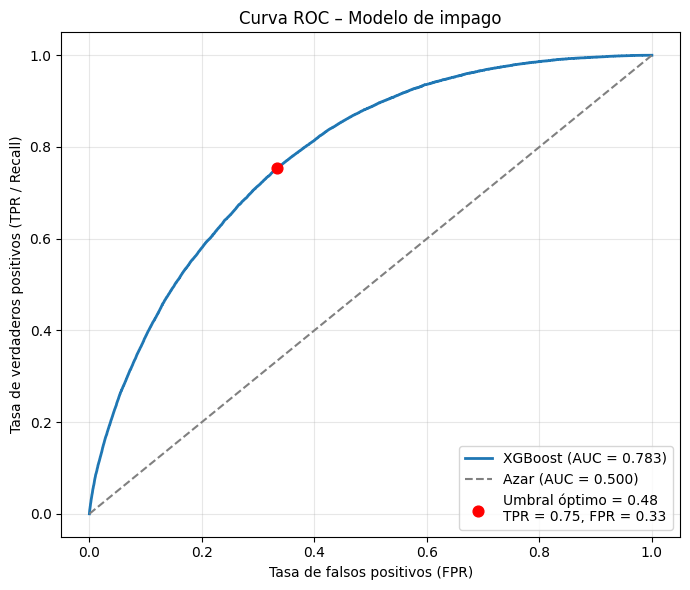

In [71]:
from sklearn.metrics import roc_curve, roc_auc_score

proba = modelo_final.predict_proba(X_test)[:, 1]
fpr, tpr, umbrales = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)

# Punto óptimo (índice de Youden: maximiza TPR - FPR)
i = np.argmax(tpr - fpr)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, lw=2, label=f'XGBoost (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], '--', color='gray', label='Azar (AUC = 0.500)')
ax.scatter(fpr[i], tpr[i], s=60, color='red', zorder=3,
           label=f'Umbral óptimo = {umbrales[i]:.2f}\nTPR = {tpr[i]:.2f}, FPR = {fpr[i]:.2f}')

ax.set_xlabel('Tasa de falsos positivos (FPR)')
ax.set_ylabel('Tasa de verdaderos positivos (TPR / Recall)')
ax.set_title('Curva ROC – Modelo de impago')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


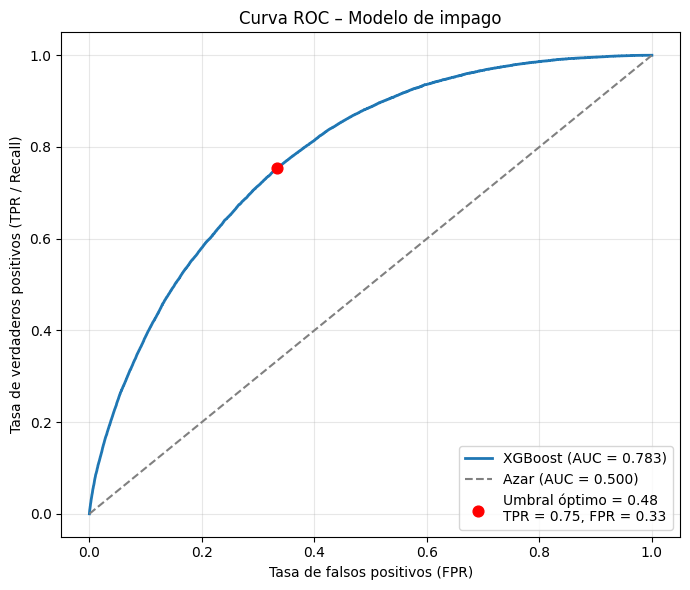

In [72]:
from sklearn.metrics import roc_curve, roc_auc_score

proba = modelo_final.predict_proba(X_test)[:, 1]
fpr, tpr, umbrales = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)

# Punto óptimo (índice de Youden: maximiza TPR - FPR)
i = np.argmax(tpr - fpr)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, lw=2, label=f'XGBoost (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], '--', color='gray', label='Azar (AUC = 0.500)')
ax.scatter(fpr[i], tpr[i], s=60, color='red', zorder=3,
           label=f'Umbral óptimo = {umbrales[i]:.2f}\nTPR = {tpr[i]:.2f}, FPR = {fpr[i]:.2f}')

ax.set_xlabel('Tasa de falsos positivos (FPR)')
ax.set_ylabel('Tasa de verdaderos positivos (TPR / Recall)')
ax.set_title('Curva ROC – Modelo de impago')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


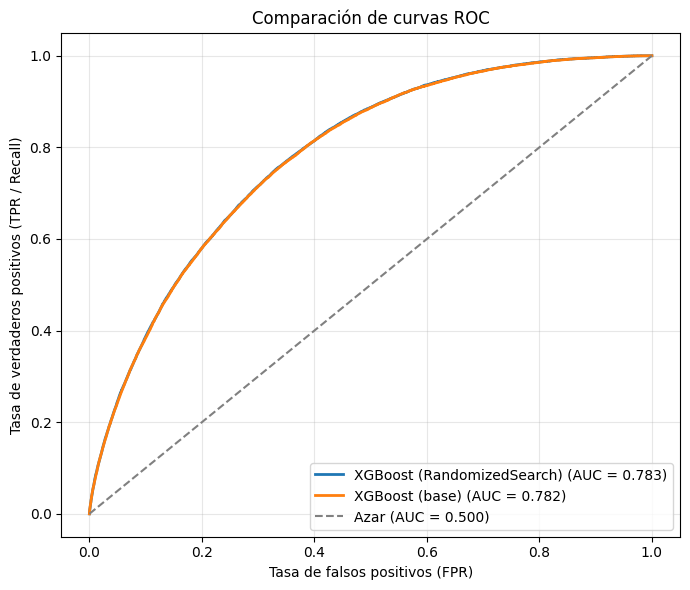

In [73]:
modelos_comparar = {
    'XGBoost (RandomizedSearch)': modelo_final,
    'XGBoost (base)': modelo_xgb,
    # 'Logística': pipe_logistica,   # descomenta si guardaste el pipeline de la logística
}

fig, ax = plt.subplots(figsize=(7, 6))
for nombre, m in modelos_comparar.items():
    p = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, lw=2, label=f'{nombre} (AUC = {roc_auc_score(y_test, p):.3f})')

ax.plot([0, 1], [0, 1], '--', color='gray', label='Azar (AUC = 0.500)')
ax.set_xlabel('Tasa de falsos positivos (FPR)')
ax.set_ylabel('Tasa de verdaderos positivos (TPR / Recall)')
ax.set_title('Comparación de curvas ROC')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


<Axes: >

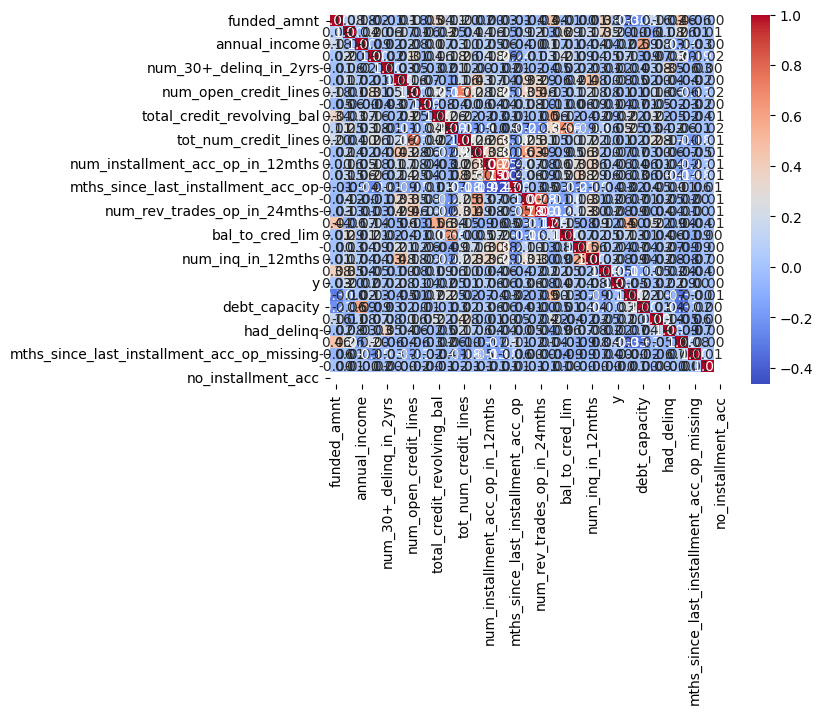

In [74]:
df.corr(numeric_only=True)

sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")

In [75]:
dfR = df.copy()

In [76]:
dfR.drop('y', axis=1, inplace=True)

In [77]:
df['Loss'] = 100 * df['max_bal_owed'] / df['funded_amnt']


In [78]:
dfR.drop('max_bal_owed', axis=1, inplace=True)


In [79]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import xgboost as xgb

# 1. Target y features (sin la columna con la que se calcula Loss)
yR = dfR['Loss']
XR = dfR.drop(columns=['Loss', 'max_bal_owed'], errors='ignore')

XR_train, XR_test, yR_train, yR_test = train_test_split(XR, yR, test_size=0.2, random_state=42)

cat_cols = XR_train.select_dtypes(include=['object', 'string']).columns.tolist()
num_cols = XR_train.select_dtypes(include='number').columns.tolist()

def evaluar(nombre, y_real, y_pred):
    print(f'===== {nombre} =====')
    print('MAE :', round(mean_absolute_error(y_real, y_pred), 2))
    print('RMSE:', round(mean_squared_error(y_real, y_pred) ** 0.5, 2))
    print('R²  :', round(r2_score(y_real, y_pred), 4), '\n')

# 2. Línea base: predecir siempre la media (cualquier modelo útil debe ganarle)
evaluar('Baseline (media)', yR_test, np.full(len(yR_test), yR_train.mean()))

# 3. Regresión lineal regularizada (Ridge)
prep = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])
ridge = TransformedTargetRegressor(            # entrena sobre log(1+Loss) porque Loss está sesgada
    regressor=Pipeline([('prep', prep), ('reg', Ridge(alpha=1.0))]),
    func=np.log1p, inverse_func=np.expm1)
ridge.fit(XR_train, yR_train)
evaluar('Ridge', yR_test, ridge.predict(XR_test))

# 4. XGBoost regresor
for X in (XR_train, XR_test):
    X[cat_cols] = X[cat_cols].astype('category')

XR_tr, XR_val, yR_tr, yR_val = train_test_split(XR_train, yR_train, test_size=0.15, random_state=42)

modelo_xgb_reg = xgb.XGBRegressor(
    n_estimators=3000, learning_rate=0.05, max_depth=6, min_child_weight=50,
    subsample=0.8, colsample_bytree=0.8,
    objective='reg:squarederror', eval_metric='rmse',
    tree_method='hist', enable_categorical=True,
    early_stopping_rounds=100, n_jobs=-1, random_state=42)
modelo_xgb_reg.fit(XR_tr, yR_tr, eval_set=[(XR_val, yR_val)], verbose=200)

pred_xgb = modelo_xgb_reg.predict(XR_test)
evaluar('XGBoost', yR_test, pred_xgb)


===== Baseline (media) =====
MAE : 28.86
RMSE: 42.28
R²  : -0.0 



===== Ridge =====
MAE : 24.23
RMSE: 365.37
R²  : -73.6711 



[0]	validation_0-rmse:41.58375


[200]	validation_0-rmse:24.55508


[400]	validation_0-rmse:24.30947


[600]	validation_0-rmse:24.22970


[800]	validation_0-rmse:24.19567


[1000]	validation_0-rmse:24.17773


[1196]	validation_0-rmse:24.17908


===== XGBoost =====
MAE : 15.39
RMSE: 24.39
R²  : 0.6673 



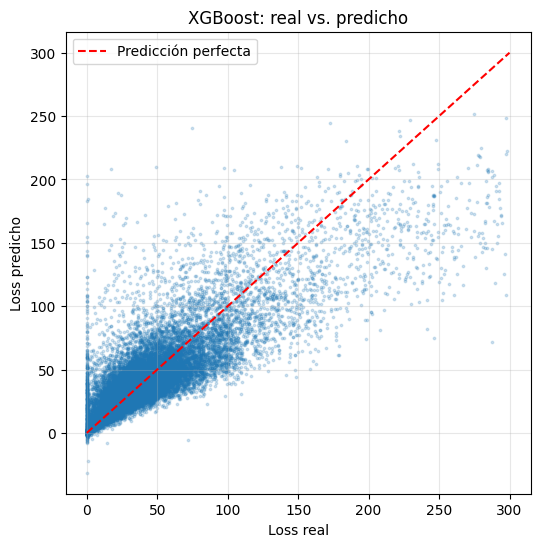

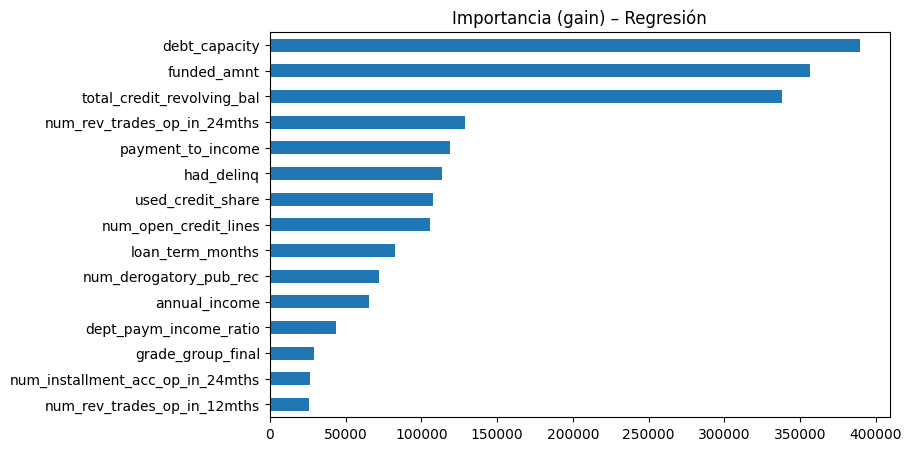

In [80]:
muestra = np.random.RandomState(42).choice(len(yR_test), 20_000, replace=False)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(yR_test.iloc[muestra], pred_xgb[muestra], s=3, alpha=0.2)
ax.plot([0, 300], [0, 300], '--', color='red', label='Predicción perfecta')
ax.set_xlabel('Loss real'); ax.set_ylabel('Loss predicho')
ax.set_title('XGBoost: real vs. predicho')
ax.legend(); ax.grid(alpha=0.3)
plt.show()

imp = pd.Series(modelo_xgb_reg.get_booster().get_score(importance_type='gain')).sort_values()
imp.tail(15).plot(kind='barh', figsize=(8, 5), title='Importancia (gain) – Regresión')
plt.show()


In [81]:
from sklearn.model_selection import RandomizedSearchCV, KFold
from scipy.stats import randint, uniform, loguniform

# Muestra de 200k filas para que la búsqueda no tarde horas
XR_s = XR_train.sample(200_000, random_state=42)
yR_s = yR_train.loc[XR_s.index]

base_reg = xgb.XGBRegressor(
    n_estimators=500,            # fijo durante la búsqueda
    objective='reg:squarederror',
    tree_method='hist',
    enable_categorical=True,
    n_jobs=-1,
    random_state=42,
)

param_dist_reg = {
    'max_depth':        randint(4, 12),
    'learning_rate':    loguniform(0.02, 0.2),
    'min_child_weight': randint(1, 300),
    'subsample':        uniform(0.6, 0.4),     # 0.6 – 1.0
    'colsample_bytree': uniform(0.5, 0.5),     # 0.5 – 1.0
    'reg_lambda':       loguniform(0.1, 50),
    'reg_alpha':        loguniform(1e-3, 10),
    'gamma':            uniform(0, 5),
    'max_bin':          [256, 512],
}

busqueda_reg = RandomizedSearchCV(
    base_reg, param_dist_reg,
    n_iter=30,
    scoring='neg_root_mean_squared_error',   # minimiza el RMSE
    cv=KFold(3, shuffle=True, random_state=42),
    n_jobs=1,
    verbose=2,
    random_state=42,
)
busqueda_reg.fit(XR_s, yR_s)

print('Mejor RMSE (CV):', round(-busqueda_reg.best_score_, 2))
print('Mejores parámetros:', busqueda_reg.best_params_)

res = pd.DataFrame(busqueda_reg.cv_results_).sort_values('rank_test_score')
res['RMSE'] = -res['mean_test_score']
res[['params', 'RMSE', 'std_test_score']].head(10)


Fitting 3 folds for each of 30 candidates, totalling 90 fits


[CV] END colsample_bytree=0.6872700594236812, gamma=4.75357153204958, learning_rate=0.10790061933340454, max_bin=256, max_depth=8, min_child_weight=103, reg_alpha=0.06071989493441298, reg_lambda=0.18613553803796204, subsample=0.7836995567863468; total time=   8.5s


[CV] END colsample_bytree=0.6872700594236812, gamma=4.75357153204958, learning_rate=0.10790061933340454, max_bin=256, max_depth=8, min_child_weight=103, reg_alpha=0.06071989493441298, reg_lambda=0.18613553803796204, subsample=0.7836995567863468; total time=   8.6s


[CV] END colsample_bytree=0.6872700594236812, gamma=4.75357153204958, learning_rate=0.10790061933340454, max_bin=256, max_depth=8, min_child_weight=103, reg_alpha=0.06071989493441298, reg_lambda=0.18613553803796204, subsample=0.7836995567863468; total time=   8.4s


[CV] END colsample_bytree=0.6668543055695109, gamma=0.7143340896097039, learning_rate=0.08951966918518126, max_bin=256, max_depth=5, min_child_weight=294, reg_alpha=0.0010071984838809194, reg_lambda=47.63753013193288, subsample=0.8469926038510867; total time=   5.4s


...

[CV] END colsample_bytree=0.9460232775885566, gamma=3.1556931299863145, learning_rate=0.12469277760338895, max_bin=512, max_depth=4, min_child_weight=284, reg_alpha=0.47391039915187827, reg_lambda=21.496231813735584, subsample=0.6920741072966221; total time=   3.6s


[CV] END colsample_bytree=0.9460232775885566, gamma=3.1556931299863145, learning_rate=0.12469277760338895, max_bin=512, max_depth=4, min_child_weight=284, reg_alpha=0.47391039915187827, reg_lambda=21.496231813735584, subsample=0.6920741072966221; total time=   3.6s


[CV] END colsample_bytree=0.9460232775885566, gamma=3.1556931299863145, learning_rate=0.12469277760338895, max_bin=512, max_depth=4, min_child_weight=284, reg_alpha=0.47391039915187827, reg_lambda=21.496231813735584, subsample=0.6920741072966221; total time=   3.6s


Mejor RMSE (CV): 24.66
Mejores parámetros: {'colsample_bytree': np.float64(0.7648252891780032), 'gamma': np.float64(1.2092614545022584), 'learning_rate': np.float64(0.024781795193130812), 'max_bin': 512, 'max_depth': 8, 'min_child_weight': 37, 'reg_alpha': np.float64(3.3926993279225184), 'reg_lambda': np.float64(0.3230835342373818), 'subsample': np.float64(0.7115485410368727)}


,params,RMSE,std_test_score
24,"{'colsample_bytree': 0.7648252891780032, 'gamm...",24.662092,0.190861
5,"{'colsample_bytree': 0.8049983288913105, 'gamm...",24.675755,0.193319
23,"{'colsample_bytree': 0.8676080596203861, 'gamm...",24.773963,0.205218
20,"{'colsample_bytree': 0.8360677737029393, 'gamm...",24.780091,0.227255
18,"{'colsample_bytree': 0.6258911479126821, 'gamm...",24.799420,0.210374
21,"{'colsample_bytree': 0.908215936609692, 'gamma...",24.805988,0.216869
12,"{'colsample_bytree': 0.6179924598744779, 'gamm...",24.806032,0.204875
1,"{'colsample_bytree': 0.6668543055695109, 'gamm...",24.835792,0.225352
22,"{'colsample_bytree': 0.7560465291496405, 'gamm...",24.846210,0.217846
3,"{'colsample_bytree': 0.5453032172664104, 'gamm...",24.851203,0.204425


In [82]:
params = {k: v for k, v in busqueda_reg.best_params_.items() if k != 'learning_rate'}

modelo_xgb_reg_final = xgb.XGBRegressor(
    **params,
    learning_rate=busqueda_reg.best_params_['learning_rate'] / 2,   # más lento = un poco más preciso
    n_estimators=5000,
    early_stopping_rounds=150,
    objective='reg:squarederror',
    eval_metric='rmse',
    tree_method='hist',
    enable_categorical=True,
    n_jobs=-1,
    random_state=42,
)
modelo_xgb_reg_final.fit(XR_tr, yR_tr, eval_set=[(XR_val, yR_val)], verbose=250)
print('Mejor iteración:', modelo_xgb_reg_final.best_iteration)

pred_final = modelo_xgb_reg_final.predict(XR_test)
evaluar('XGBoost (antes)', yR_test, pred_xgb)
evaluar('XGBoost (RandomizedSearch)', yR_test, pred_final)


[0]	validation_0-rmse:42.07340


[250]	validation_0-rmse:25.21391


[500]	validation_0-rmse:24.45651


[750]	validation_0-rmse:24.25780


[1000]	validation_0-rmse:24.17086


...

[2750]	validation_0-rmse:24.06391


[3000]	validation_0-rmse:24.06030


[3205]	validation_0-rmse:24.06025


Mejor iteración: 3055


===== XGBoost (antes) =====
MAE : 15.39
RMSE: 24.39
R²  : 0.6673 

===== XGBoost (RandomizedSearch) =====
MAE : 15.3
RMSE: 24.27
R²  : 0.6705 



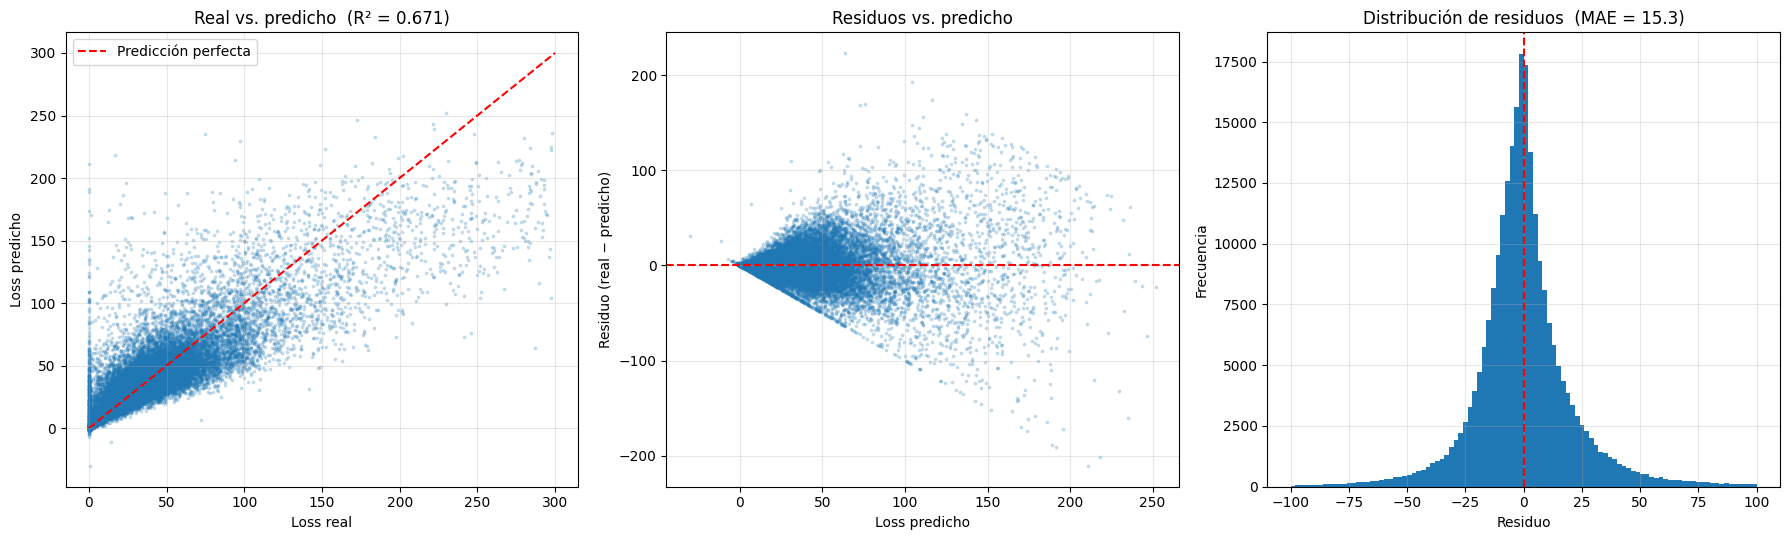

In [83]:
residuos = yR_test.values - pred_final
muestra = np.random.RandomState(42).choice(len(yR_test), 20_000, replace=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Real vs. predicho
ax = axes[0]
ax.scatter(yR_test.values[muestra], pred_final[muestra], s=3, alpha=0.2)
ax.plot([0, 300], [0, 300], '--', color='red', label='Predicción perfecta')
ax.set_xlabel('Loss real'); ax.set_ylabel('Loss predicho')
ax.set_title(f'Real vs. predicho  (R² = {r2_score(yR_test, pred_final):.3f})')
ax.legend(); ax.grid(alpha=0.3)

# 2. Residuos vs. predicho
ax = axes[1]
ax.scatter(pred_final[muestra], residuos[muestra], s=3, alpha=0.2)
ax.axhline(0, color='red', ls='--')
ax.set_xlabel('Loss predicho'); ax.set_ylabel('Residuo (real − predicho)')
ax.set_title('Residuos vs. predicho'); ax.grid(alpha=0.3)

# 3. Distribución de los residuos
ax = axes[2]
ax.hist(residuos, bins=100, range=(-100, 100), edgecolor='none')
ax.axvline(0, color='red', ls='--')
ax.set_xlabel('Residuo'); ax.set_ylabel('Frecuencia')
ax.set_title(f'Distribución de residuos  (MAE = {mean_absolute_error(yR_test, pred_final):.1f})')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


                               MAE     RMSE      R²
Media (baseline)            28.862   42.282  -0.000
Ridge                       24.231  365.368 -73.671
XGBoost                     15.387   24.388   0.667
XGBoost (RandomizedSearch)  15.299   24.270   0.671


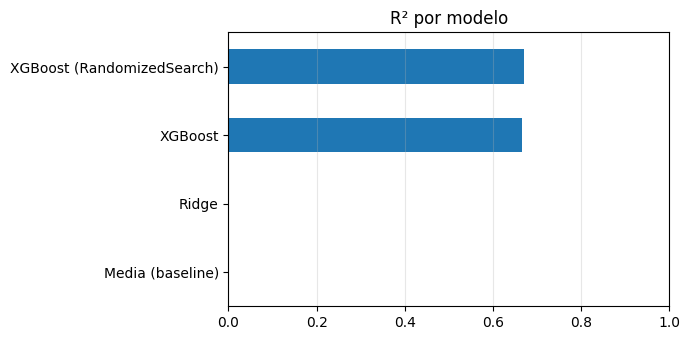

In [84]:
resultados = {
    'Media (baseline)': np.full(len(yR_test), yR_train.mean()),
    'Ridge': ridge.predict(XR_test.astype({c: 'object' for c in cat_cols})),
    'XGBoost': pred_xgb,
    'XGBoost (RandomizedSearch)': pred_final,
}
tabla = pd.DataFrame({n: {'MAE': mean_absolute_error(yR_test, p),
                          'RMSE': mean_squared_error(yR_test, p) ** 0.5,
                          'R²': r2_score(yR_test, p)} for n, p in resultados.items()}).T.round(3)
print(tabla)

tabla['R²'].plot(kind='barh', figsize=(7, 3.5), title='R² por modelo', xlim=(0, 1))
plt.grid(alpha=0.3, axis='x'); plt.tight_layout(); plt.show()


In [85]:
comunes = X_test.index.intersection(XR_test.index)
print(len(comunes))


50322


In [86]:
pd_raw = modelo_final.predict_proba(X_test.loc[comunes])[:, 1]

print('PD promedio del modelo:', pd_raw.mean())
print('Tasa real de impago   :', y_test.loc[comunes].mean())


PD promedio del modelo: 0.39121416
Tasa real de impago   : 0.10075116251341362


In [87]:
lgd_raw = modelo_xgb_reg_final.predict(XR_test.loc[comunes])   # Loss en porcentaje (0–300)
lgd = np.clip(lgd_raw / 100, 0, 1)                             # pasar a fracción y recortar entre 0 y 1

print('LGD promedio:', round(lgd.mean(), 4), '| min:', lgd.min(), '| max:', lgd.max())
print('% de préstamos recortados en 1:', round((lgd_raw > 100).mean() * 100, 2))


LGD promedio: 0.4304 | min: 0.0 | max: 1.0
% de préstamos recortados en 1: 7.61


In [88]:
# 1. Loans that are in both tests
comunes = X_test.index.intersection(XR_test.index)

# 2. Calibrated PD
pd_raw = modelo_final.predict_proba(X_test.loc[comunes])[:, 1]
w = modelo_final.get_params()['scale_pos_weight']
pd_cal = pd_raw / (pd_raw + w * (1 - pd_raw))

# 3. LGD
lgd_raw = modelo_xgb_reg_final.predict(XR_test.loc[comunes])
lgd = np.clip(lgd_raw / 100, 0, 1)

# 4. EAD and expected loss per loan
ead = df.loc[comunes, 'funded_amnt'].values
el = pd_cal * lgd * ead
resultado = pd.DataFrame({'PD': pd_cal, 'LGD': lgd, 'EAD': ead, 'EL': el}, index=comunes)

# 5. Total for the portfolio
total_ead = resultado['EAD'].sum()
total_el  = resultado['EL'].sum()

print(f'Préstamos        : {len(resultado):,}')
print(f'PD calibrada     : {pd_cal.mean():.4f}  vs real {y_test.loc[comunes].mean():.4f}')
print(f'Exposición total : ${total_ead:,.0f}')
print(f'Pérdida esperada : ${total_el:,.0f}')
print(f'Tasa de pérdida  : {total_el / total_ead:.2%}')



Préstamos        : 50,322
PD calibrada     : 0.0967  vs real 0.1008
Exposición total : $749,066,400
Pérdida esperada : $24,308,067
Tasa de pérdida  : 3.25%


In [89]:
resultado['grade'] = df.loc[comunes, 'grade_group_final']
resultado['y_real'] = y_test.loc[comunes]

orden = ['A+', 'A-', 'B+', 'B-', 'C+', 'C-', 'D+', 'D-', 'EFG']

por_grado = resultado.groupby('grade').agg(
    n=('EL', 'size'),
    PD_predicha=('PD', 'mean'),
    PD_real=('y_real', 'mean'),       # lo que pasó de verdad
    LGD=('LGD', 'mean'),
    EL_total=('EL', 'sum'),
    EAD_total=('EAD', 'sum'),
).reindex(orden)
por_grado['tasa_perdida'] = por_grado['EL_total'] / por_grado['EAD_total']
por_grado.round(4)


,n,PD_predicha,PD_real,LGD,EL_total,EAD_total,tasa_perdida
grade,,,,,,,
A+,6025,0.0180,0.0181,0.4859,6.398667e+05,88225100,0.0073
A-,4485,0.0314,0.0359,0.4702,7.952873e+05,64816425,0.0123
B+,8503,0.0562,0.0593,0.4562,2.541905e+06,121261150,0.0210
B-,6600,0.0793,0.0894,0.4510,2.584117e+06,92023200,0.0281
C+,9245,0.1037,0.1047,0.4234,4.765275e+06,136102950,0.0350
C-,5531,0.1304,0.1345,0.3950,3.627749e+06,86504350,0.0419
D+,4666,0.1553,0.1582,0.3840,3.427106e+06,72543475,0.0472
D-,2026,0.1738,0.1732,0.3760,1.708495e+06,31734825,0.0538
EFG,3241,0.2652,0.2792,0.3441,4.218266e+06,55854925,0.0755


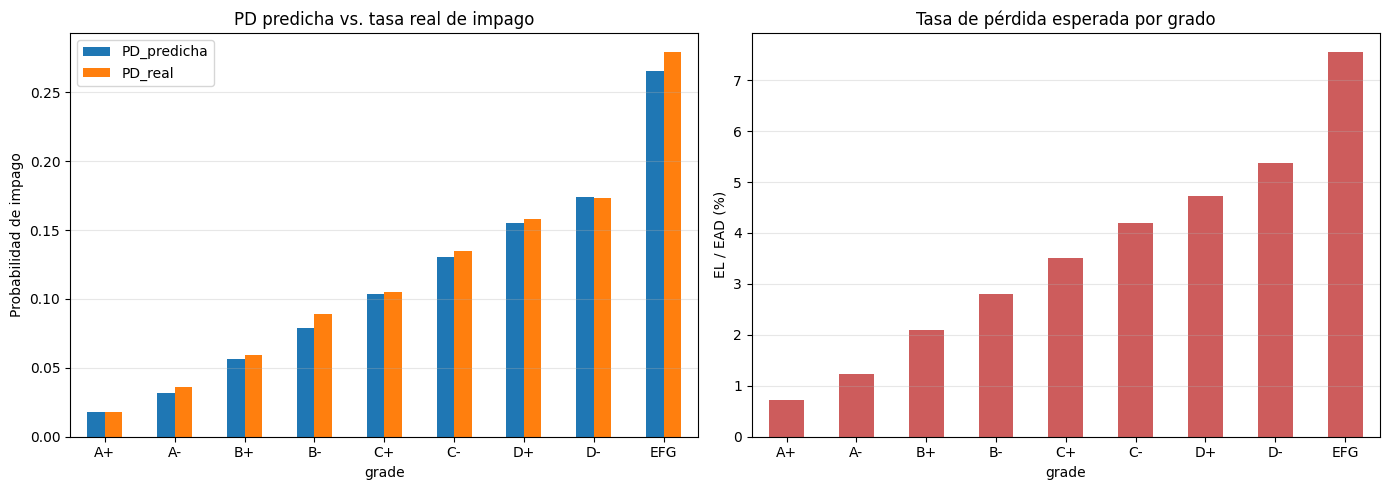

In [90]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

por_grado[['PD_predicha', 'PD_real']].plot(kind='bar', ax=axes[0], rot=0)
axes[0].set_title('PD predicha vs. tasa real de impago')
axes[0].set_ylabel('Probabilidad de impago')
axes[0].grid(alpha=0.3, axis='y')

(por_grado['tasa_perdida'] * 100).plot(kind='bar', ax=axes[1], rot=0, color='indianred')
axes[1].set_title('Tasa de pérdida esperada por grado')
axes[1].set_ylabel('EL / EAD (%)')
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


In [91]:
# 1. Unir train + test de cada modelo (ya están transformados)
X_all  = pd.concat([X_train, X_test]).sort_index()
XR_all = pd.concat([XR_train, XR_test]).loc[X_all.index]
y_all  = pd.concat([y_train, y_test]).loc[X_all.index]

# Al unir, las columnas categóricas pueden perder su tipo; se lo devolvemos
for c in X_all.select_dtypes(include=['object', 'string', 'category']).columns:
    X_all[c] = X_all[c].astype(X_train[c].dtype)
for c in XR_all.select_dtypes(include=['object', 'string', 'category']).columns:
    XR_all[c] = XR_all[c].astype(XR_train[c].dtype)

print('Préstamos:', len(X_all))

# 2. PD calibrada, LGD, EAD y EL (los mismos pasos que antes)
pd_raw_all = modelo_final.predict_proba(X_all)[:, 1]
pd_all  = pd_raw_all / (pd_raw_all + w * (1 - pd_raw_all))
lgd_all = np.clip(modelo_xgb_reg_final.predict(XR_all) / 100, 0, 1)
ead_all = df.loc[X_all.index, 'funded_amnt'].values

cartera = pd.DataFrame({'PD': pd_all, 'LGD': lgd_all, 'EAD': ead_all,
                        'EL': pd_all * lgd_all * ead_all,
                        'y_real': y_all.values,
                        'grade': df.loc[X_all.index, 'grade_group_final'].values},
                       index=X_all.index)

# 3. Resultado de toda la cartera
print(f"Exposición total : ${cartera['EAD'].sum():,.0f}")
print(f"Pérdida esperada : ${cartera['EL'].sum():,.0f}")
print(f"Tasa de pérdida  : {cartera['EL'].sum() / cartera['EAD'].sum():.2%}")
print(f"PD promedio      : {cartera['PD'].mean():.4f}  vs real {cartera['y_real'].mean():.4f}")


Préstamos: 1257995


Exposición total : $18,824,571,450
Pérdida esperada : $610,118,503
Tasa de pérdida  : 3.24%
PD promedio      : 0.0966  vs real 0.1017


In [92]:
import joblib, os

ruta = r'C:\Users\Diego Monegro\Downloads\api_riesgo\artefactos'
os.makedirs(ruta, exist_ok=True)

modelo_final.save_model(os.path.join(ruta, 'modelo_pd.json'))
modelo_xgb_reg_final.save_model(os.path.join(ruta, 'modelo_lgd.json'))

meta = {
    'cols_pd':  X_train.columns.tolist(),
    'cats_pd':  {c: X_train[c].cat.categories.tolist() for c in X_train.select_dtypes('category')},
    'cols_lgd': XR_train.columns.tolist(),
    'cats_lgd': {c: XR_train[c].cat.categories.tolist() for c in XR_train.select_dtypes('category')},
    'p01': p01, 'p99': p99,
    'log_cols': log_cols, 'clip_cols': clip_cols, 'bin_cols': bin_cols,
    'w': float(modelo_final.get_params()['scale_pos_weight']),
    'medianas': {c: float(df[c].median()) for c in ['mths_since_last_installment_acc_op', 'bal_to_cred_lim']},
}
joblib.dump(meta, os.path.join(ruta, 'meta.joblib'))
print('PD :', meta['cols_pd'])
print('LGD:', meta['cols_lgd'])


PD : ['funded_amnt', 'interest_rate', 'home_ownership_status', 'annual_income', 'verification_status', 'dept_paym_income_ratio', 'num_30+_delinq_in_2yrs', 'num_inq_in_6mths', 'num_open_credit_lines', 'num_derogatory_pub_rec', 'total_credit_revolving_bal', 'used_credit_share', 'tot_num_credit_lines', 'initial_list_status', 'num_open_trades_in_6mths', 'num_installment_acc_op_in_12mths', 'num_installment_acc_op_in_24mths', 'mths_since_last_installment_acc_op', 'num_rev_trades_op_in_12mths', 'num_rev_trades_op_in_24mths', 'max_bal_owed', 'bal_to_cred_lim', 'num_inq', 'num_inq_in_12mths', 'disbursement_method', 'loan_term_months', 'issue_date_year', 'earliest_cr_line_year', 'Loss', 'employment_sector', 'loan_purpose_group', 'emp_length_group', 'state_region', 'debt_capacity', 'grade_group_final', 'credit_age', 'had_delinq', 'payment_to_income', 'mths_since_last_installment_acc_op_missing', 'bal_to_cred_lim_missing']
LGD: ['funded_amnt', 'interest_rate', 'home_ownership_status', 'annual_inco

In [93]:
import sys
sys.path.insert(0, r'C:\Users\Diego Monegro\Downloads\api_riesgo')
from features import construir_base, preparar_pd, preparar_lgd

raw = pd.read_csv(r"d:\SQL\Jyts DS Course\Notebooks\X.csv", low_memory=False)
raw = raw[(100 * raw['max_bal_owed'] / raw['funded_amnt']) < 300].reset_index(drop=True)

idx = X_test.index[:2000]
p_api = modelo_final.predict_proba(preparar_pd(construir_base(raw.loc[idx], meta), meta))[:, 1]
p_nb  = modelo_final.predict_proba(X_test.loc[idx])[:, 1]
print('PD  – max difference:', np.abs(p_api - p_nb).max())

idx = XR_test.index[:2000]
l_api = modelo_xgb_reg_final.predict(preparar_lgd(construir_base(raw.loc[idx], meta), meta))
l_nb  = modelo_xgb_reg_final.predict(XR_test.loc[idx])
print('LGD – max difference:', np.abs(l_api - l_nb).max())


PD  – max difference: 0.0


LGD – max difference: 0.0


# Correcciones finales

Al revisar el proyecto completo aparecieron dos problemas que cambian la cifra final. Esta sección los corrige **sin modificar las celdas anteriores**, que se conservan como historial del proceso.

1. **El modelo de PD incluía `issue_date_year` y `earliest_cr_line_year`.** El split se ejecutó antes de la celda que las eliminaba. `issue_date_year` era la variable más importante del modelo, pero su señal es un **sesgo temporal**: los préstamos de 2018 tienen solo un 2,9 % de impago porque todavía no han tenido tiempo de caer en mora, no porque sean mejores clientes. Un modelo así subestimaría el riesgo de cualquier préstamo nuevo.
2. **El modelo de LGD se entrenó con todos los préstamos.** La Fase 3 pide entrenarlo **solo con los morosos** (`y = 1`), que es la definición de *Loss Given Default*: la pérdida *dado que* hubo impago.

Además, la pérdida esperada se calcula ahora sobre **todo el conjunto de Test de la PD** (251.599 préstamos), como pide la Fase 4. Como la LGD se entrena solo con morosos del *train*, ninguno de los dos modelos ha visto esos préstamos.


[0]	validation_0-aucpr:0.21441


[500]	validation_0-aucpr:0.26995


[1000]	validation_0-aucpr:0.27535


[1500]	validation_0-aucpr:0.27705


[2000]	validation_0-aucpr:0.27749


[2035]	validation_0-aucpr:0.27745


                             ROC-AUC    Gini  PR-AUC  Recall (0.5)  \
PD v1 (con issue_date_year)   0.7830  0.5659  0.2881        0.7335   
PD v2 (sin fechas)            0.7801  0.5602  0.2832        0.7217   

                             Precisión (0.5)  
PD v1 (con issue_date_year)           0.2085  
PD v2 (sin fechas)                    0.2097  

Umbrales (PD v2):
  0.3: recall = 0.919 | precisión = 0.154
  0.4: recall = 0.843 | precisión = 0.178


  0.5: recall = 0.722 | precisión = 0.210
  0.6: recall = 0.550 | precisión = 0.253
  0.7: recall = 0.341 | precisión = 0.315

Top 8 variables (gain):
grade_group_final              528.6
disbursement_method            355.0
interest_rate                  160.8
num_rev_trades_op_in_24mths     83.9
verification_status             81.6
num_inq_in_6mths                78.9
num_30+_delinq_in_2yrs          71.7
home_ownership_status           69.5
dtype: float64


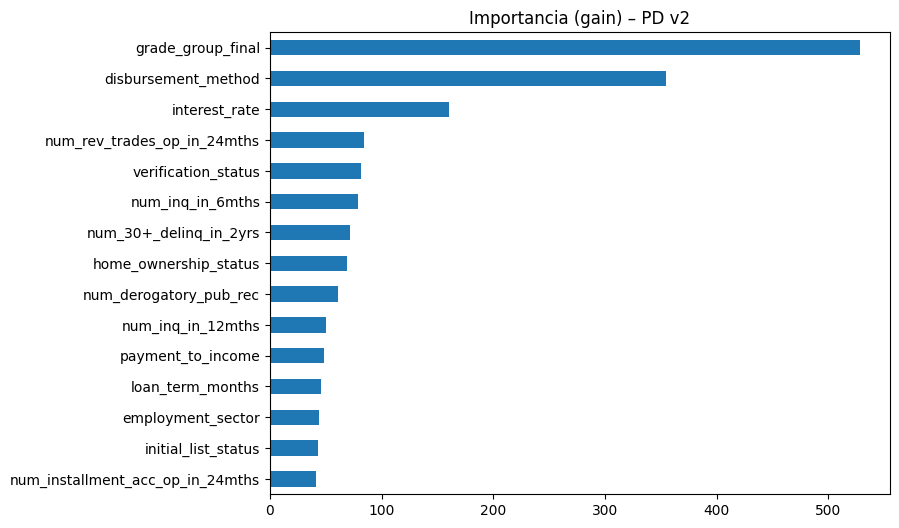

In [94]:
# ============================================================
# CORRECCIÓN 1 – Modelo de PD sin variables de fecha
# ============================================================
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score, precision_score

cols_fecha = ['issue_date_year', 'earliest_cr_line_year']
X_train_v2 = X_train.drop(columns=cols_fecha, errors='ignore')
X_test_v2  = X_test.drop(columns=cols_fecha, errors='ignore')

X_tr2, X_val2, y_tr2, y_val2 = train_test_split(
    X_train_v2, y_train, test_size=0.15, stratify=y_train, random_state=42)
w2 = (y_tr2 == 0).sum() / (y_tr2 == 1).sum()

# Mejores parámetros del RandomizedSearchCV de clasificación (celda anterior)
mejores_pd = {'colsample_bytree': 0.8047821669899484, 'gamma': 2.5133951161443076,
              'learning_rate': 0.022516907664967046, 'max_depth': 7, 'min_child_weight': 129,
              'reg_lambda': 0.3558271615421386, 'subsample': 0.6579579488364892}

modelo_pd_v2 = xgb.XGBClassifier(
    **mejores_pd, n_estimators=3000, early_stopping_rounds=100,
    tree_method='hist', enable_categorical=True, scale_pos_weight=w2,
    eval_metric='aucpr', n_jobs=-1, random_state=42)
modelo_pd_v2.fit(X_tr2, y_tr2, eval_set=[(X_val2, y_val2)], verbose=500)

proba_v1 = modelo_final.predict_proba(X_test)[:, 1]
proba_v2 = modelo_pd_v2.predict_proba(X_test_v2)[:, 1]

comparacion_pd = pd.DataFrame({
    nombre: {'ROC-AUC': roc_auc_score(y_test, p),
             'Gini': 2 * roc_auc_score(y_test, p) - 1,
             'PR-AUC': average_precision_score(y_test, p),
             'Recall (0.5)': recall_score(y_test, p >= 0.5),
             'Precisión (0.5)': precision_score(y_test, p >= 0.5)}
    for nombre, p in [('PD v1 (con issue_date_year)', proba_v1), ('PD v2 (sin fechas)', proba_v2)]
}).T.round(4)
print(comparacion_pd)

print('\nUmbrales (PD v2):')
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    print(f'  {t}: recall = {recall_score(y_test, proba_v2 >= t):.3f} | '
          f'precisión = {precision_score(y_test, proba_v2 >= t):.3f}')

imp_v2 = pd.Series(modelo_pd_v2.get_booster().get_score(importance_type='gain')).sort_values()
print('\nTop 8 variables (gain):'); print(imp_v2.tail(8)[::-1].round(1))
imp_v2.tail(15).plot(kind='barh', figsize=(8, 6), title='Importancia (gain) – PD v2')
plt.show()


In [95]:
# ============================================================
# CORRECCIÓN 2 – Modelo de LGD entrenado solo con morosos (y = 1)
# ============================================================
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import randint, uniform, loguniform

# Mismas variables que el modelo de regresión anterior, para todos los préstamos
XR_all = pd.concat([XR_train, XR_test])
for c in XR_train.select_dtypes('category').columns:
    XR_all[c] = XR_all[c].astype(XR_train[c].dtype)
yR_all = pd.concat([yR_train, yR_test])

# Morosos del TRAIN de la PD para entrenar; morosos del TEST de la PD para evaluar.
# Así ningún préstamo del test lo ha visto ni el modelo de PD ni el de LGD.
idx_tr = y_train.index[y_train == 1]
idx_te = y_test.index[y_test == 1]
XL_train, yL_train = XR_all.loc[idx_tr], yR_all.loc[idx_tr]
XL_test,  yL_test  = XR_all.loc[idx_te], yR_all.loc[idx_te]
print('Morosos para entrenar:', len(XL_train), '| para evaluar:', len(XL_test))

def metricas(y_real, y_pred):
    return {'MAE': mean_absolute_error(y_real, y_pred),
            'RMSE': mean_squared_error(y_real, y_pred) ** 0.5,
            'R²': r2_score(y_real, y_pred)}

resultados_lgd = {'Baseline (media)': metricas(yL_test, np.full(len(yL_test), yL_train.mean()))}

busqueda_lgd = RandomizedSearchCV(
    xgb.XGBRegressor(n_estimators=500, objective='reg:squarederror', tree_method='hist',
                     enable_categorical=True, n_jobs=-1, random_state=42),
    {'max_depth': randint(4, 12), 'learning_rate': loguniform(0.02, 0.2),
     'min_child_weight': randint(1, 300), 'subsample': uniform(0.6, 0.4),
     'colsample_bytree': uniform(0.5, 0.5), 'reg_lambda': loguniform(0.1, 50),
     'reg_alpha': loguniform(1e-3, 10), 'gamma': uniform(0, 5)},
    n_iter=15, scoring='neg_root_mean_squared_error',
    cv=KFold(3, shuffle=True, random_state=42), n_jobs=1, random_state=42)
busqueda_lgd.fit(XL_train, yL_train)
print('Mejores parámetros LGD:', busqueda_lgd.best_params_)

XL_tr, XL_val, yL_tr, yL_val = train_test_split(XL_train, yL_train, test_size=0.15, random_state=42)
modelo_lgd_v2 = xgb.XGBRegressor(
    **busqueda_lgd.best_params_, n_estimators=5000, early_stopping_rounds=150,
    objective='reg:squarederror', eval_metric='rmse', tree_method='hist',
    enable_categorical=True, n_jobs=-1, random_state=42)
modelo_lgd_v2.fit(XL_tr, yL_tr, eval_set=[(XL_val, yL_val)], verbose=500)

resultados_lgd['XGBoost (solo morosos)'] = metricas(yL_test, modelo_lgd_v2.predict(XL_test))
print(pd.DataFrame(resultados_lgd).T.round(3))


Morosos para entrenar: 102382 | para evaluar: 25595


Mejores parámetros LGD: {'colsample_bytree': np.float64(0.9436063712881633), 'gamma': np.float64(2.3610746258097466), 'learning_rate': np.float64(0.026340513770510204), 'max_depth': 9, 'min_child_weight': 131, 'reg_alpha': np.float64(1.1044350847124695), 'reg_lambda': np.float64(3.2724296605909378), 'subsample': np.float64(0.9083868719818244)}
[0]	validation_0-rmse:38.50503


[500]	validation_0-rmse:22.72752


[648]	validation_0-rmse:22.76781


                           MAE    RMSE     R²
Baseline (media)        26.177  39.206 -0.000
XGBoost (solo morosos)  14.048  23.088  0.653


Préstamos        : 251,599
PD calibrada     : 0.0934  vs real 0.1017
LGD promedio     : 0.4263
Exposición total : $3,767,660,700
Pérdida esperada : $117,253,894
Tasa de pérdida  : 3.11%
           n  PD_predicha  PD_real     LGD      EL_total  EAD_total  tasa_perdida  pct_EAD  pct_EL
grade                                                                                             
A+     29892       0.0170   0.0183  0.4788  3.000981e+06  441721225        0.0068   0.1172  0.0256
A-     22613       0.0303   0.0341  0.4630  3.898841e+06  332054275        0.0117   0.0881  0.0333
B+     42868       0.0537   0.0600  0.4532  1.227371e+07  612764075        0.0200   0.1626  0.1047
B-     32717       0.0767   0.0862  0.4448  1.251840e+07  459523375        0.0272   0.1220  0.1068
C+     45888       0.1003   0.1092  0.4215  2.276003e+07  675705300        0.0337   0.1793  0.1941
C-     27863       0.1255   0.1346  0.3942  1.748809e+07  435584500        0.0401   0.1156  0.1491
D+     22894       0.1

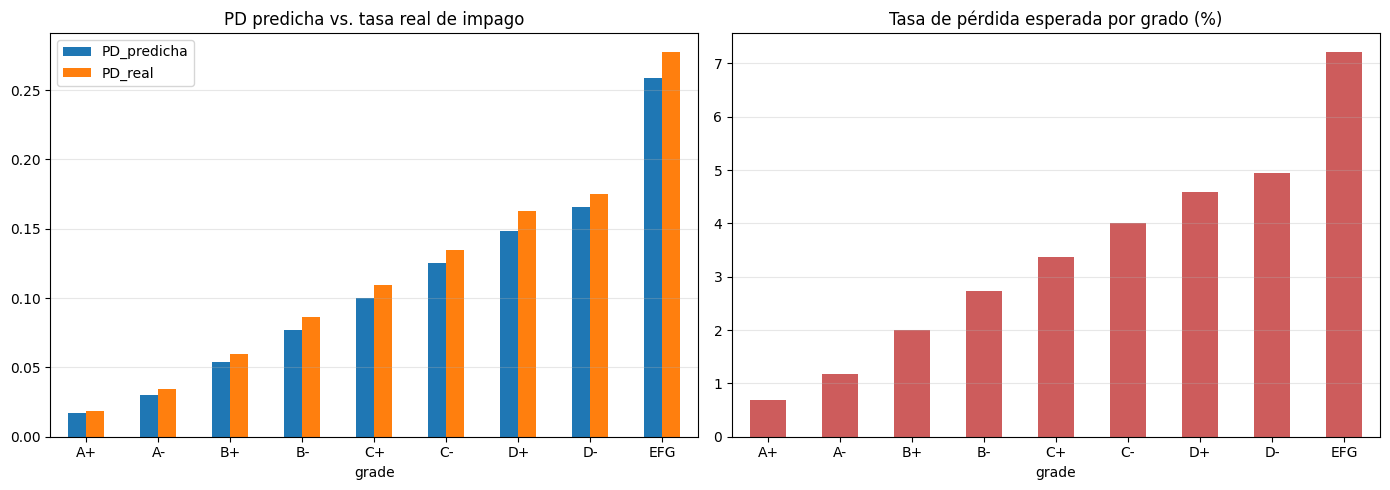

In [96]:
# ============================================================
# FASE 4 (definitiva) – Pérdida esperada sobre TODO el test de la PD
# ============================================================
pd_raw_test = modelo_pd_v2.predict_proba(X_test_v2)[:, 1]
pd_test  = pd_raw_test / (pd_raw_test + w2 * (1 - pd_raw_test))        # calibración
lgd_test = np.clip(modelo_lgd_v2.predict(XR_all.loc[X_test.index]) / 100, 0, 1)
ead_test = df.loc[X_test.index, 'funded_amnt'].values

resultado_v2 = pd.DataFrame({
    'PD': pd_test, 'LGD': lgd_test, 'EAD': ead_test, 'EL': pd_test * lgd_test * ead_test,
    'y_real': y_test.values,
    'grade': df.loc[X_test.index, 'grade_group_final'].values,
}, index=X_test.index)

total_ead_v2 = resultado_v2['EAD'].sum()
total_el_v2  = resultado_v2['EL'].sum()
print(f"Préstamos        : {len(resultado_v2):,}")
print(f"PD calibrada     : {resultado_v2['PD'].mean():.4f}  vs real {resultado_v2['y_real'].mean():.4f}")
print(f"LGD promedio     : {resultado_v2['LGD'].mean():.4f}")
print(f"Exposición total : ${total_ead_v2:,.0f}")
print(f"Pérdida esperada : ${total_el_v2:,.0f}")
print(f"Tasa de pérdida  : {total_el_v2 / total_ead_v2:.2%}")

orden = ['A+', 'A-', 'B+', 'B-', 'C+', 'C-', 'D+', 'D-', 'EFG']
por_grado_v2 = resultado_v2.groupby('grade').agg(
    n=('EL', 'size'), PD_predicha=('PD', 'mean'), PD_real=('y_real', 'mean'),
    LGD=('LGD', 'mean'), EL_total=('EL', 'sum'), EAD_total=('EAD', 'sum')).reindex(orden)
por_grado_v2['tasa_perdida'] = por_grado_v2['EL_total'] / por_grado_v2['EAD_total']
por_grado_v2['pct_EAD'] = por_grado_v2['EAD_total'] / total_ead_v2
por_grado_v2['pct_EL'] = por_grado_v2['EL_total'] / total_el_v2
print(por_grado_v2.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
por_grado_v2[['PD_predicha', 'PD_real']].plot(kind='bar', ax=axes[0], rot=0)
axes[0].set_title('PD predicha vs. tasa real de impago'); axes[0].grid(alpha=0.3, axis='y')
(por_grado_v2['tasa_perdida'] * 100).plot(kind='bar', ax=axes[1], rot=0, color='indianred')
axes[1].set_title('Tasa de pérdida esperada por grado (%)'); axes[1].grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()


In [97]:
# ============================================================
# Exportar los modelos corregidos para la API
# ============================================================
import joblib, os

ruta = r'C:\Users\Diego Monegro\Downloads\api_riesgo\artefactos'
os.makedirs(ruta, exist_ok=True)

modelo_pd_v2.save_model(os.path.join(ruta, 'modelo_pd.json'))
modelo_lgd_v2.save_model(os.path.join(ruta, 'modelo_lgd.json'))

meta_v2 = joblib.load(os.path.join(ruta, 'meta.joblib'))
meta_v2['cols_pd'] = X_train_v2.columns.tolist()
meta_v2['w'] = float(w2)
joblib.dump(meta_v2, os.path.join(ruta, 'meta.joblib'))
print('Modelos v2 exportados en', ruta)


Modelos v2 exportados en C:\Users\Diego Monegro\Downloads\api_riesgo\artefactos


# Conclusiones para el Comité

> **Señores del Comité, de una cartera de Test valorada en 3.767,7 millones de dólares, nuestro motor estima que tendremos unas pérdidas por impago de 117,3 millones de dólares (3,11 % de la exposición).**

La cartera de Test son los **251.599 préstamos** que no se usaron para entrenar ni el modelo de PD ni el de LGD.

### Los tres componentes

| Componente | Modelo | Resultado en Test |
|---|---|---|
| **PD** | XGBoost calibrado, sin variables de fecha | ROC-AUC **0,780** · Gini 0,560 · PR-AUC 0,283 · Recall 0,722 |
| **LGD** | XGBoost entrenado **solo con morosos** (`y = 1`) | MAE **14,05** · RMSE 23,09 · R² 0,653 (línea base: MAE 26,18) |
| **EAD** | `funded_amnt` | 3.767,7 millones de dólares |

### Por qué estos modelos

- **PD:** XGBoost superó a la regresión logística (AUC 0,769) y a HistGradientBoosting (0,779). Para cumplir la prioridad del CRO, *"prefiero rechazar a un cliente regular que dejar pasar a un moroso"*, el umbral se puede bajar a 0,3: el Recall sube a **0,919** sin reentrenar.
- **Se eliminó `issue_date_year`:** era la variable más importante del modelo, pero solo porque los préstamos recientes **aún no han tenido tiempo de caer en impago** (18,6 % de morosidad en 2015 frente a 2,9 % en 2018). Al quitarla, el AUC solo baja de 0,783 a 0,780, y el modelo deja de depender de un efecto que no se repetirá con préstamos nuevos.
- **Calibración:** `scale_pos_weight` inflaba la PD media hasta 0,39. Se corrigió con $PD = p / (p + w(1-p))$; sin ese paso, la pérdida se habría sobreestimado unas 4 veces.
- **LGD:** se entrenó con los 102.382 morosos del train y se evaluó con los 25.595 morosos del test, como pide la Fase 3. Se equivoca en promedio en 14 puntos de `Loss`, frente a 26 de la línea base.

### Insights

1. **La pérdida esperada es del 3,11 %:** de cada 100 dólares, se esperan perder 3,11.
2. **El riesgo sube de forma monótona con el grado:** la tasa de pérdida pasa de **0,68 % (A+)** a **7,21 % (E–G)**.
3. **La pérdida se concentra en los grados bajos:** E, F y G son el **7,6 % de la exposición**, pero generan el **17,7 % de la pérdida**. Excluirlos o exigirles más interés reduce el riesgo de la compra de forma desproporcionada.
4. **La PD subestima ligeramente:** predice 9,34 % frente al 10,17 % real, y queda por debajo en todos los grados. Con un ajuste prudente (× 1,089), la pérdida sería de unos **127,7 millones (3,39 %)**. Recomendamos reservar con esta cifra.

### ¿Es explicable ante el regulador?

XGBoost es menos transparente que una regresión logística, pero se puede auditar: su PD sigue la tasa observada en cada grado, el riesgo crece de forma monótona y las variables más importantes (`grade_group_final`, `interest_rate`, `verification_status`, consultas de crédito y moras recientes) tienen sentido de negocio. La regresión logística queda como **modelo de referencia** explicable (1 punto de AUC menos), y el siguiente paso es **SHAP** para justificar cada decisión individual.

### Limitaciones

- **`Loss` es un proxy de la LGD:** usa la deuda en tarjetas *previa* al préstamo, no las recuperaciones reales. La LGD baja en los grados de mayor riesgo (0,48 en A+, 0,34 en E–G), por lo que la pérdida de esos grados probablemente está subestimada.
- **`disbursement_method` también refleja la fecha:** el 91 % de los préstamos *DirectPay* son de 2018. Es la 2.ª variable más importante y conviene revisarla en una próxima versión.
- **Población:** el filtro `Loss < 300` deja fuera ~880.000 préstamos sin historial completo.
